# 15 · Full-photo detector comparison and crop inspection

**Question.** The app's pipeline is *detector → line grouping → reading order → crop → S1 reader*. The detector, `PP-OCRv5_mobile_det`, was inherited from the earlier pipeline. Nobody checked that it suits our whiteboard photos. This notebook compares two pipelines that differ **only in the detector**:

| arm | detector | everything after detection |
|---|---|---|
| **mobile** (app today) | `PP-OCRv5_mobile_det` | app code, unchanged |
| **server** (candidate) | `PP-OCRv5_server_det` | the same app code |
| *annotation boxes* (control) | none: the annotation quads | S1 on the annotation quads, in reference order |

**S1** is our fine-tuned `PP-OCRv5_server_rec`, exported from run S1 (seed 1). It is the same file, with the same resize and the same CPU settings, in every arm.

**How this differs from notebook 14.** Notebook 14 used crops that had already been prepared. This notebook starts from the **16 full Jy photos** (Photo 8–23), so the boxes, line grouping and crops are all made by the app's own code.

**Ground truth status. Read this before the numbers.**
- The answer keys are **provisional**: `provisional_assistant_reviewed`, and `human_owner_approved = False`. The assistant reviewed them visually, and it had already seen OCR outputs, so this was not a blind audit.
- The annotation quads mark where the teammates' crop images sit inside each photo (SIFT/RANSAC placement). They show where each word was cut, **not** an independent, tight outline of the ink.

**Two kinds of numbers, kept apart.**
1. **Page CER (main).** The whole-photo text, in the app's own order, compared with the reference page. It uses no annotation geometry and counts missed text, extra text, recognition errors and ordering together.
2. **Diagnostics.** Anything that links predicted boxes to annotation quads: coverage, missed/extra/merged regions, GT-assisted reordering, and the recognition-only control. These explain the main number. They are *not* app accuracy, and overlap coverage is **not** detection recall.

**Three questions.**
1. Does `server_det` improve detection and final OCR enough to justify its extra time and memory?
2. Do the app's crops have the excess-margin problem seen in notebook 14?
3. Do the errors come from detection, line grouping, cropping, reading order or recognition?

The decision rules were frozen in `outputs/detector_comparison/PROTOCOL.json` before any server output was opened. No training was run, the app was not changed, and no crop was tightened.

**How the results were produced.** On the Mac, in the app's environment (`.venv-paddle`, Paddle 3.3.1), from the Assignment folder:
```
.venv-paddle/bin/python whiteboard-ocr/scripts/run_detector_comparison.py
```
- Each arm runs in its own process, so model load time and memory are measured cleanly.
- A finished arm is reused only when its cache key matches: images, answer keys, settings, code hashes, model hashes and environment.
- This notebook only reads the saved outputs. Its analysis code is in `whiteboard-ocr/scripts/detector_comparison_analysis.py`.

In [1]:
from pathlib import Path
import json, sys, hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image as IPImage
pd.set_option('display.max_colwidth', 80); pd.set_option('display.width', 200)

ASSIGNMENT_OVERRIDE = None          # set to your Assignment folder if the search below fails
cands = [Path(ASSIGNMENT_OVERRIDE)] if ASSIGNMENT_OVERRIDE else []
for base in [Path.cwd(), *Path.cwd().parents]:
    cands += [base, base / 'Assignment']
A = next(p.resolve() for p in cands if (p / 'whiteboard-ocr/outputs/detector_comparison/PROTOCOL.json').is_file())
WO = A / 'whiteboard-ocr'; BASE = WO / 'outputs/detector_comparison'; VIS = BASE / 'analysis'
sys.path.insert(0, str(WO / 'scripts'))
import detector_comparison_analysis as da
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()

P = json.loads((BASE / 'PROTOCOL.json').read_text())
keys, arms = da.load(BASE)
MOB, SRV, GT = 'PP-OCRv5_mobile_det', 'PP-OCRv5_server_det', 'gt_quads'
assert set(arms) == {MOB, SRV, GT}, f'missing arms: {set([MOB, SRV, GT]) - set(arms)}; run the runner first'
assert P['answer_keys_sha256'] == sha(da.KEYS) == arms[MOB]['run']['cache_key']['answer_keys_sha256'], 'answer keys changed'
for a in arms.values():
    assert a['run']['no_training'] and not a['run']['app_modified'] and not a['run']['crops_tightened']
    assert a['run']['cache_key']['answer_keys_sha256'] == P['answer_keys_sha256']
ev = da.evaluate(keys, arms)
R = pd.DataFrame(da.region_table(keys, arms, ev))
T = pd.DataFrame(da.target_table(keys, ev))
print('Protocol:', P['status'])
print(f"Answer keys: {keys['status']}, owner approved = {keys['human_owner_approved']}; "
      f"{sum(len(p['lines']) for p in keys['photos'])} targets, {sum(len(da.norm(p['reference'])) for p in keys['photos'])} reference characters, {len(keys['photos'])} photos")

Protocol: frozen while the Mac run was in progress, BEFORE any PP-OCRv5_server_det output was opened or scored (mobile_det results from earlier app runs had been seen)
Answer keys: provisional_assistant_reviewed, owner approved = False; 300 targets, 3975 reference characters, 16 photos


## 1 · What was run: identities and settings

The reader must be byte-identical across the arms; the cell asserts it.

**Detector settings.** The app passes `thresh 0.20`, `box_thresh 0.40` and `unclip_ratio 1.2`. It runs a quick pass with the long side limited to 1600 px, then a full-resolution retry if the writing is under 20 px. Both detectors get exactly these values through the app's own `Detector` class. Settings the app does *not* pass fall back to each model's `inference.yml` defaults, so the second table lists every place where those defaults differ.

In [2]:
ids = []
for arm in (MOB, SRV, GT):
    r = arms[arm]['run']; ck = r['cache_key']; df = ck.get('detector_files') or {}
    params = df.get('inference.pdiparams', {})
    ids.append(dict(arm=da.SHORT[arm], created=r['created'],
                    detector=r['detector'] or '(annotation quads)',
                    detector_params_sha256=params.get('sha256', '')[:16],
                    detector_files_MB=round(sum(v['bytes'] for v in df.values()) / 2**20, 1) if df else None,
                    reader=r['reader_identity']['model_id'], reader_params_sha256=r['reader_identity']['params_sha256'][:16],
                    reader_input=str(r['reader_identity']['image_shape']), paddle=ck['env']['paddlepaddle'],
                    paddleocr=ck['env']['paddleocr'], paddlex=ck['env']['paddlex'], platform=ck['env']['platform'],
                    runner_sha256=ck['runner_sha256'][:12], backend_sha256=ck['backend_sha256'][:12]))
display(pd.DataFrame(ids).set_index('arm').T)
ri = [arms[a]['run']['reader_identity'] for a in (MOB, SRV, GT)]
assert all(x == ri[0] for x in ri), 'reader differs between arms'
assert len({arms[a]['run']['cache_key']['backend_sha256'] for a in arms}) == 1, 'app backend changed between arms'
print('S1 reader identical in all three arms (graph, params, config, input shape, runtime, threads).')

arm,mobile,server,annotation boxes
created,2026-11-09 02:25:52 +08,2026-11-09 02:33:44 +08,2026-11-09 02:23:03 +08
detector,PP-OCRv5_mobile_det,PP-OCRv5_server_det,(annotation quads)
detector_params_sha256,afa1820cb16c1fd0,183146fe9d991035,
detector_files_MB,4.7,84.3,NaN
reader,S1,S1,S1
reader_params_sha256,067b34a571b6f152,067b34a571b6f152,067b34a571b6f152
reader_input,"[3, 64, 1024]","[3, 64, 1024]","[3, 64, 1024]"
paddle,3.3.1,3.3.1,3.3.1
paddleocr,3.7.0,3.7.0,3.7.0
paddlex,3.7.2,3.7.2,3.7.2


S1 reader identical in all three arms (graph, params, config, input shape, runtime, threads).


In [3]:
def flat(x, k=''):
    if isinstance(x, dict):
        return {kk: vv for a, v in x.items() for kk, vv in flat(v, f'{k}.{a}' if k else str(a)).items()}
    if isinstance(x, list):
        out = {}
        for i, v in enumerate(x):
            name = next(iter(v)) if isinstance(v, dict) and len(v) == 1 else str(i)
            out.update(flat(v, f'{k}.{name}' if k else name))
        return out
    return {k: x}
ea, eb = arms[MOB]['run']['detector_effective_args'], arms[SRV]['run']['detector_effective_args']
print('Arguments the app passes to both detectors (identical):', ea == eb, ea)
print('Per call: unclip_ratio 1.2; limit_side_len 1600 (quick pass) or 4000 (retry), limit_type "max".')
ya = flat({k: v for k, v in (arms[MOB]['run']['detector_inference_yml'] or {}).items() if k in ('PreProcess', 'PostProcess')})
yb = flat({k: v for k, v in (arms[SRV]['run']['detector_inference_yml'] or {}).items() if k in ('PreProcess', 'PostProcess')})
OVERRIDDEN = ('thresh', 'box_thresh', 'unclip_ratio', 'limit_side_len', 'limit_type')
diff = [dict(setting=k, mobile=ya.get(k), server=yb.get(k),
             used_at_runtime='overridden by the app (identical for both)' if k.split('.')[-1] in OVERRIDDEN else 'model default (differs)')
        for k in sorted(set(ya) | set(yb)) if ya.get(k) != yb.get(k)]
display(pd.DataFrame(diff) if diff else Markdown('**No pre/post-processing defaults differ between the two models.**'))

Arguments the app passes to both detectors (identical): True {'thresh': 0.2, 'box_thresh': 0.4, 'unclip_ratio': 1.2}
Per call: unclip_ratio 1.2; limit_side_len 1600 (quick pass) or 4000 (retry), limit_type "max".


**No pre/post-processing defaults differ between the two models.**

## 2 · Speed and memory

- **Load** = building the model object, plus downloading it the first time.
- **First call** = the first detection after loading (warm-up). Both are reported separately and are **not** included in per-photo processing.
- **Per-photo detection** = the median of 3 repeats on the same photo.
- The **app path** per photo = image load + detection + grouping + ordering + cropping + S1 reading. This is what a user waits for once the models are loaded.
- Peak memory is the peak resident memory of each arm's process (S1 plus the detector). The control arm has S1 only, so the difference from it estimates what each detector adds.

These timings come from one run on the Mac CPU (S1 with 4 threads; the detector at PaddleX's default CPU settings). Treat small differences as noise.

arm,mobile,server,annotation boxes
reader load s,1.713501,1.574346,2.834185
detector load s,3.018961,17.396462,NaN
detector first call s,0.545825,8.522086,NaN
detection s/photo (median),0.491575,5.836757,NaN
"detection s, 16 photos",7.840008,93.291986,NaN
group+order ms/photo,0.75518,4.374391,NaN
crop ms/photo,1.026372,7.345193,1.582529
S1 read s/photo,4.354746,4.947295,4.339556
S1 read ms/region,231.481512,262.10835,231.443008
app path s/photo (mean),4.850944,10.808932,NaN


server/mobile detection time: 11.9x ; app path: 2.23x


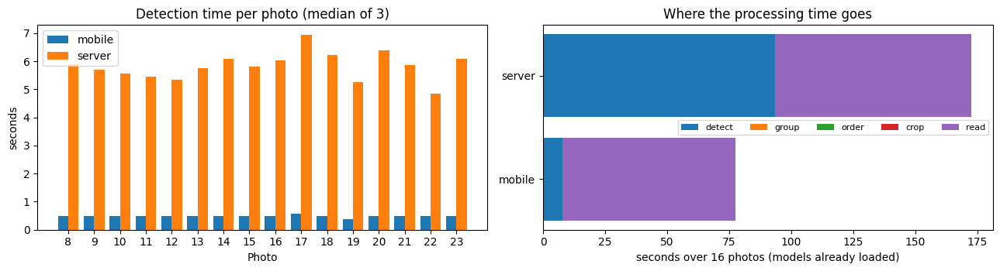

In [4]:
def ptab(arm):
    ph = arms[arm]['photos'].values()
    return pd.DataFrame([dict(photo=p['photo_id'], detect=p.get('detect_seconds'), group=p.get('group_seconds'), order=p.get('order_seconds'),
                              crop=p['crop_seconds'], read=p['recognition_seconds'], regions=len(p['grouped']),
                              app_path=p.get('app_path_seconds'), deterministic=p.get('detect_deterministic')) for p in ph])
tm = []
peak_gt = arms[GT]['run']['memory_mb']['end_maxrss_mb']
for arm in (MOB, SRV, GT):
    r = arms[arm]['run']; t = r['timings']; m = r['memory_mb']; d = ptab(arm)
    tm.append({'arm': da.SHORT[arm], 'reader load s': t['reader_load_seconds'], 'detector load s': t['detector_load_seconds'],
               'detector first call s': t['detector_first_call_seconds'],
               'detection s/photo (median)': d['detect'].median() if arm != GT else None,
               'detection s, 16 photos': d['detect'].sum() if arm != GT else None,
               'group+order ms/photo': 1000 * (d['group'] + d['order']).mean() if arm != GT else None,
               'crop ms/photo': 1000 * d['crop'].mean(), 'S1 read s/photo': d['read'].mean(),
               'S1 read ms/region': 1000 * d['read'].sum() / d['regions'].sum(),
               'app path s/photo (mean)': d['app_path'].mean() if arm != GT else None,
               'peak RSS MB': m['end_maxrss_mb'], 'peak RSS above S1-only MB': m['end_maxrss_mb'] - peak_gt if arm != GT else 0.0,
               'detection deterministic': bool(d['deterministic'].all()) if arm != GT else None})
TM = pd.DataFrame(tm).set_index('arm')
display(TM.T)
dm, ds = ptab(MOB).set_index('photo'), ptab(SRV).set_index('photo')
print(f"server/mobile detection time: {ds['detect'].sum() / dm['detect'].sum():.1f}x ; app path: {ds['app_path'].sum() / dm['app_path'].sum():.2f}x")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
x = np.arange(len(dm)); w = .4
ax[0].bar(x - w/2, dm['detect'], w, label='mobile'); ax[0].bar(x + w/2, ds['detect'], w, label='server')
ax[0].set_xticks(x, dm.index); ax[0].set_xlabel('Photo'); ax[0].set_ylabel('seconds'); ax[0].set_title('Detection time per photo (median of 3)'); ax[0].legend()
parts = ['detect', 'group', 'order', 'crop', 'read']
bottom = np.zeros(2)
for p_ in parts:
    v = np.array([dm[p_].sum(), ds[p_].sum()]); ax[1].barh(['mobile', 'server'], v, left=bottom, label=p_); bottom += v
ax[1].set_xlabel('seconds over 16 photos (models already loaded)'); ax[1].set_title('Where the processing time goes'); ax[1].legend(ncol=5, fontsize=8)
plt.tight_layout(); plt.show()

## 3 · Main result: real full-page CER (no annotation geometry)

For each photo, S1's lines are joined in the app's own reading order and compared with the reference page. Text is lower-cased and whitespace collapsed; the edit distance is uncapped. Every returned region counts, including text that isn't on the board (insertions).

The difference between the detectors is computed with a **paired photo bootstrap**: whole photos are resampled, since 16 photos is a small sample.

In [5]:
main = []
for arm in (MOB, SRV):
    c = da.corpus(ev[arm]); main.append(dict(pipeline=f'{da.SHORT[arm]}_det -> S1 (app order)', page_errors=c['page_errors'],
        reference_chars=c['chars'], page_CER=c['page_CER'], regions=c['regions']))
display(pd.DataFrame(main).set_index('pipeline').round(4))
pt, lo, hi = da.paired_bootstrap(ev[MOB], ev[SRV])
print(f'page CER, server - mobile: {100*pt:+.2f} points (95% photo-bootstrap CI {100*lo:+.2f} .. {100*hi:+.2f})')
pp = pd.DataFrame([dict(photo=pid, chars=ev[MOB][pid]['grouped']['chars'],
                        mobile_CER=ev[MOB][pid]['grouped']['page_errors'] / ev[MOB][pid]['grouped']['chars'],
                        server_CER=ev[SRV][pid]['grouped']['page_errors'] / ev[SRV][pid]['grouped']['chars'],
                        mobile_regions=len(arms[MOB]['photos'][pid]['grouped']), server_regions=len(arms[SRV]['photos'][pid]['grouped']))
                   for pid in sorted(ev[MOB])])
pp['server - mobile'] = pp['server_CER'] - pp['mobile_CER']
display(pp.set_index('photo').round(3))
gc = da.corpus(ev[GT])
print(f"Control (not a pipeline): S1 on the annotation quads, reference order: page CER {gc['page_CER']:.4f} ({gc['page_errors']}/{gc['chars']}) = recognition-only floor")

,page_errors,reference_chars,page_CER,regions
pipeline,,,,
mobile_det -> S1 (app order),1094,3975,0.2752,301
server_det -> S1 (app order),1016,3975,0.2556,302


page CER, server - mobile: -1.96 points (95% photo-bootstrap CI -6.39 .. +0.57)


,chars,mobile_CER,server_CER,mobile_regions,server_regions,server - mobile
photo,,,,,,
8,342,0.740,0.757,38,39,0.018
9,330,0.030,0.042,10,10,0.012
10,375,0.040,0.037,7,7,-0.003
11,376,0.032,0.035,7,7,0.003
12,201,0.050,0.040,26,26,-0.010
13,62,0.081,0.081,3,3,0.000
14,373,0.729,0.507,50,50,-0.223
15,364,0.736,0.742,43,43,0.005
16,254,0.083,0.059,9,9,-0.024


Control (not a pipeline): S1 on the annotation quads, reference order: page CER 0.0470 (187/3975) = recognition-only floor


In [6]:
# Reproduction check: the mobile arm should reproduce the app's earlier full-photo run (same Mac, same code path).
old = WO / 'outputs/jy_ocr_evaluation/full_photos'
same_boxes = same_text = n = 0
for pid, rec in arms[MOB]['photos'].items():
    o = old / 'S1' / f'Photo_{pid}.json'
    if not o.exists():
        continue
    o = json.loads(o.read_text()); n += 1
    same_boxes += bool(len(o['lines']) == len(rec['grouped']) and np.allclose([l['box'] for l in o['lines']], [r['box'] for r in rec['grouped']], atol=.01))
    same_text += o['text'] == rec['text']
print(f'Earlier app run (outputs/jy_ocr_evaluation/full_photos, S1): identical boxes on {same_boxes}/{n} photos, identical text on {same_text}/{n}')

Earlier app run (outputs/jy_ocr_evaluation/full_photos, S1): identical boxes on 16/16 photos, identical text on 16/16


## 4 · Diagnostics that use the annotation quads

**Matching rule.** This is the same rule as `scripts/score_jy_annotated_photos.py`, written down before these results.
- A predicted box and an annotation quad are **linked** if either holds (both measured on convex hulls):
  - IoU ≥ 0.25, or
  - intersection ÷ the smaller area ≥ 0.50.
- Recognised text is never used for matching.
- Linked boxes and quads form connected groups ("components"):

| component | meaning |
|---|---|
| one-to-one | one target, one region |
| **merge** | several targets inside one region (lines/words merged) |
| **split** | one target cut into several regions |
| many-to-many | several of each |
| **missed target** | a target with no linked region |
| **unmatched region** | a region linked to no target: extra detection (sign, residue, noise) |

**Coverage** = targets with at least one linked region ÷ all targets. Overlap only shows that *something* was detected there. It does **not** prove that every stroke was inside the box, so it is not detection recall.

**Raw vs after grouping.** "Raw" is the detector's own boxes. "After grouping" is the app's `group_into_lines` output, which S1 actually reads. Comparing them separates detector errors from grouping errors. The raw-box readings (each raw box cropped and read by S1) are diagnostic only: the app never reads raw boxes.

**GT-assisted reordered CER.** This puts each component's text in the reference order before scoring. It removes reading-order errors and shows what the boxes and recognition alone achieve. It is not an app capability.

In [7]:
dg = []
for arm in (MOB, SRV):
    for v in ('raw', 'grouped'):
        c = da.corpus(ev[arm], v)
        dg.append({'detector': da.SHORT[arm], 'boxes': 'raw (detector)' if v == 'raw' else 'after grouping (app)',
                   'regions': c['regions'], 'coverage': c['coverage'], 'missed targets': c['missed_targets'],
                   'unmatched regions': c['unmatched_regions'], 'merge': c['merge_components'], 'split': c['split_components'],
                   'many-to-many': c['many_to_many'], 'one-to-one': c['one_to_one'],
                   'annotated-target CER': c['annotated_target_CER'], 'GT-reordered CER': c['gt_reordered_CER'], 'page CER (app order)': c['page_CER']})
c = da.corpus(ev[GT])
dg.append({'detector': 'annotation boxes', 'boxes': 'control', 'regions': c['regions'], 'coverage': c['coverage'], 'missed targets': 0,
           'unmatched regions': 0, 'merge': 0, 'split': 0, 'many-to-many': 0, 'one-to-one': c['one_to_one'],
           'annotated-target CER': c['annotated_target_CER'], 'GT-reordered CER': c['gt_reordered_CER'], 'page CER (app order)': None})
DG = pd.DataFrame(dg); display(DG.round(4))
print('Raw-box rows read each raw box separately; the app never does this (diagnostic only).')

,detector,boxes,regions,coverage,missed targets,unmatched regions,merge,split,many-to-many,one-to-one,annotated-target CER,GT-reordered CER,page CER (app order)
0,mobile,raw (detector),302,1.0,0,2,0,0,0,300,0.0517,0.0501,0.2752
1,mobile,after grouping (app),301,1.0,0,2,1,0,0,298,0.0515,0.0564,0.2752
2,server,raw (detector),304,1.0,0,2,0,2,0,298,0.0534,0.0516,0.2556
3,server,after grouping (app),302,1.0,0,2,0,0,0,300,0.0534,0.0516,0.2556
4,annotation boxes,control,300,1.0,0,0,0,0,0,300,0.0507,0.0470,NaN


Raw-box rows read each raw box separately; the app never does this (diagnostic only).


In [8]:
# Every non-one-to-one component, both detectors (after grouping = what the app reads)
lst = []
for arm in (MOB, SRV):
    for pid in sorted(ev[arm]):
        for comp in ev[arm][pid]['grouped']['components']:
            if comp['kind'] != 'one_to_one':
                lst.append(dict(detector=da.SHORT[arm], photo=pid, kind=comp['kind'], targets=', '.join(comp['gt_ids']),
                                regions=comp['prediction_indices'], reference=comp['reference'], S1_text=comp['prediction'], errors=comp['errors']))
display(pd.DataFrame(lst))

,detector,photo,kind,targets,regions,reference,S1_text,errors
0,mobile,8,merge_candidate,"8.1.12, 8.2.12",[34],membrane lipoproteins,membrane lipoproteins,0
1,mobile,14,unmatched_prediction,,[1],,abelr,5
2,mobile,14,unmatched_prediction,,[2],,l,1
3,server,14,unmatched_prediction,,[1],,abe r,5
4,server,14,unmatched_prediction,,[2],,h,1


### 4b · Where do the page errors come from? (an approximate ladder)

Each rung adds one source of error. The rungs are corpus CER over all 16 photos.

1. **Recognition floor**: S1 reading the annotation quads in reference order. Only recognition errors remain, assuming the annotation boxes are good crops.
2. **+ detector boxes, grouping and cropping**: the app's regions, GT-reordered. The increase over rung 1 is what the app's boxes and crops add (or remove, if negative).
3. **+ reading order**: the app's own order, which is the real page CER. The increase over rung 2 comes from ordering, plus how extra text lands in the page.

**Grouping effect** = GT-reordered CER after grouping minus GT-reordered CER of the raw boxes.

The rungs are approximate because components are scored as whole units. Use them for "which source is large", not to split points finely.

detector,mobile (CER points),server (CER points)
1 recognition floor (annotation boxes),4.70,4.70
"2 app regions, GT-reordered",5.64,5.16
3 page CER (app order),27.52,25.56
boxes/grouping/crop effect (2-1),0.93,0.45
reading-order effect (3-2),21.89,20.40
"grouping effect (grouped - raw, GT-reordered)",0.63,0.00


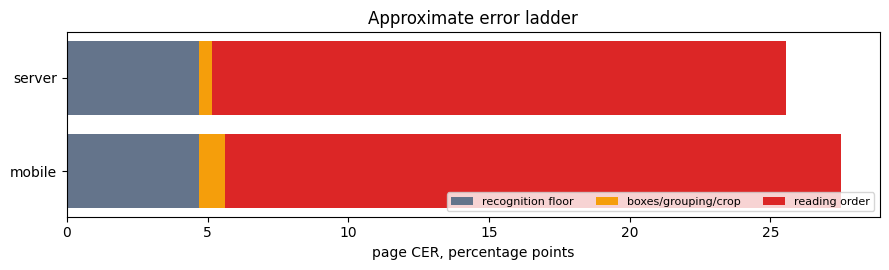

In [9]:
lad = []
floor = da.corpus(ev[GT])
for arm in (MOB, SRV):
    g, r = da.corpus(ev[arm]), da.corpus(ev[arm], 'raw')
    lad.append({'detector': da.SHORT[arm], '1 recognition floor (annotation boxes)': floor['gt_reordered_CER'],
                '2 app regions, GT-reordered': g['gt_reordered_CER'], '3 page CER (app order)': g['page_CER'],
                'boxes/grouping/crop effect (2-1)': g['gt_reordered_CER'] - floor['gt_reordered_CER'],
                'reading-order effect (3-2)': g['page_CER'] - g['gt_reordered_CER'],
                'grouping effect (grouped - raw, GT-reordered)': g['gt_reordered_CER'] - r['gt_reordered_CER']})
LAD = pd.DataFrame(lad).set_index('detector'); display((100 * LAD).round(2).T.rename(columns=lambda c: c + ' (CER points)'))
fig, ax = plt.subplots(figsize=(9, 2.8))
for i, arm in enumerate(('mobile', 'server')):
    a, b, c3 = LAD.loc[arm].iloc[0], LAD.loc[arm].iloc[1] - LAD.loc[arm].iloc[0], LAD.loc[arm].iloc[2] - LAD.loc[arm].iloc[1]
    ax.barh(arm, 100 * a, color='#64748b', label='recognition floor' if i == 0 else None)
    ax.barh(arm, 100 * b, left=100 * a, color='#f59e0b', label='boxes/grouping/crop' if i == 0 else None)
    ax.barh(arm, 100 * c3, left=100 * (a + b), color='#dc2626', label='reading order' if i == 0 else None)
ax.set_xlabel('page CER, percentage points'); ax.legend(ncol=3, fontsize=8, loc='lower right'); ax.set_title('Approximate error ladder'); plt.tight_layout(); plt.show()

**Why reading order costs so much.** The app's `spatial_order` splits the page into columns only where an empty vertical strip is wider than **1.5 × the median line height**. Otherwise all boxes are treated as one column and read row by row, which interleaves the columns. The table below recomputes that rule from the saved boxes (it is geometry only, so no inference is involved).

In [10]:
sys.path.insert(0, str(WO)); from preprocessing import text_lines as tl
col = []
for pid in sorted(ev[MOB]):
    for arm in (MOB, SRV):
        boxes = [np.float32(r['box']) for r in arms[arm]['photos'][pid]['grouped']]
        merged = []
        for x0, x1 in sorted((float(b[:, 0].min()), float(b[:, 0].max())) for b in boxes):
            if merged and x0 <= merged[-1][1]:
                merged[-1][1] = max(merged[-1][1], x1)
            else:
                merged.append([x0, x1])
        thr = max(20.0, 1.5 * float(np.median([tl.line_height(b) for b in boxes])))
        gaps = [round(c - b) for (_, b), (c, _) in zip(merged, merged[1:])]
        g = ev[arm][pid]['grouped']
        col.append(dict(photo=pid, detector=da.SHORT[arm], empty_strips_px=gaps, cut_threshold_px=round(thr),
                        columns_used=1 + sum(x > thr for x in gaps), page_CER=g['page_errors'] / g['chars'],
                        GT_reordered_CER=g['reordered_errors'] / g['chars'], order_penalty=(g['page_errors'] - g['reordered_errors']) / g['chars']))
COL = pd.DataFrame(col); display(COL.round(3))
bad = sorted(COL[(COL.detector == 'mobile') & (COL.order_penalty > .3)].photo)
print('Photos where ordering costs > 30 CER points (mobile):', bad)
e = lambda arm, excl: sum(ev[arm][p]['grouped']['page_errors'] for p in ev[arm] if p not in excl)
print(f"Page errors excluding Photo 14: mobile {e(MOB, [14])}, server {e(SRV, [14])}")
print('Strips at x = 0..35 px are the printed sign at the left edge of Photo 14 (an extra region in both arms).')

,photo,detector,empty_strips_px,cut_threshold_px,columns_used,page_CER,GT_reordered_CER,order_penalty
0,8,mobile,[31],61,1,0.740,0.120,0.620
1,8,server,"[29, 29]",54,1,0.757,0.056,0.702
2,9,mobile,[],76,1,0.030,0.030,0.000
3,9,server,[],72,1,0.042,0.042,0.000
4,10,mobile,[],63,1,0.040,0.040,0.000
5,10,server,[],63,1,0.037,0.037,0.000
6,11,mobile,[],66,1,0.032,0.032,0.000
7,11,server,[],65,1,0.035,0.035,0.000
8,12,mobile,[149],71,2,0.050,0.050,0.000
9,12,server,[147],68,2,0.040,0.040,0.000


Photos where ordering costs > 30 CER points (mobile): [8, 14, 15, 19]
Page errors excluding Photo 14: mobile 822, server 827
Strips at x = 0..35 px are the printed sign at the left edge of Photo 14 (an extra region in both arms).


### 4c · Same target, two boxes: does the app's crop hurt S1?

For each target matched **one-to-one** by a detector, S1 reads the same word twice: from the annotation quad and from the detector's region. The text and the reader are the same, so any difference comes from the box and crop alone. A positive difference means the detector's crop is worse.

In [11]:
PR = {}
for arm in (MOB, SRV):
    pr = pd.DataFrame(da.paired_targets(keys, arms, ev, arm)); PR[arm] = pr
    d, lo, hi = da.paired_target_bootstrap(pr.to_dict('records'))
    better = (pr.detector_errors < pr.annotation_box_errors).sum(); worse = (pr.detector_errors > pr.annotation_box_errors).sum()
    print(f"{da.SHORT[arm]}: {len(pr)} one-to-one targets; CER annotation box {pr.annotation_box_errors.sum()/pr.chars.sum():.4f} "
          f"vs detector box {pr.detector_errors.sum()/pr.chars.sum():.4f}; difference {100*d:+.2f} points (95% CI {100*lo:+.2f} .. {100*hi:+.2f}); "
          f"detector crop better on {better}, worse on {worse}, same on {len(pr)-better-worse}")
pm = PR[MOB]; chg = pm[pm.detector_errors != pm.annotation_box_errors].sort_values('detector_errors', ascending=False)
display(chg[['photo_id', 'gt_id', 'reference', 'annotation_box_text', 'annotation_box_errors', 'detector_text', 'detector_errors']].rename(columns={'detector_text': 'mobile_crop_text', 'detector_errors': 'mobile_crop_errors'}))

mobile: 298 one-to-one targets; CER annotation box 0.0509 vs detector box 0.0518; difference +0.08 points (95% CI -0.46 .. +0.67); detector crop better on 38, worse on 43, same on 217


server: 300 one-to-one targets; CER annotation box 0.0507 vs detector box 0.0534; difference +0.27 points (95% CI -0.24 .. +0.86); detector crop better on 33, worse on 48, same on 219


,photo_id,gt_id,reference,annotation_box_text,annotation_box_errors,mobile_crop_text,mobile_crop_errors
60,11,11.4.1,"flip, crop, colour jitter every augmented wolf is still on snow","flip, crop, colour jtter every avgmented wolf is stin on snow",4,"flip, crop, <olour jitter every avgmented woltf is stin on snow",5
186,16,16.4.1,concentrated source of energy,concemtrated source of eneryy,2,concemtrated sourre ot eneryy,4
225,19,19.1.11,rainbow,rrn ingoow,5,raniongoow,4
47,10,10.1.1,it is unsafe only when left or right is part of the label,itis unsate only when left on right is part of the label,3,itis unsate ouly when left on right is part of the label,4
37,9,9.1.1,"same photos, same 100% in training","same photos, sume ioo%. in training",5,"same photos, sume ioo% in training",4
...,...,...,...,...,...,...,...
134,14,14.3.15,ecstacy,cstacy,1,ecstacy,0
135,14,14.added.1,laughing,haughing,1,laughing,0
141,15,15.1.4,pancreatic,pancreafic,1,pancreatic,0
4,8,8.1.5,esterified,esterifiel,1,esterified,0


## 5 · Question 2: do the app's crops have notebook 14's excess-margin problem?

The measure is notebook 14's ink rule:
- a sensitive ink mask finds the writing;
- the ink box is padded by max(6 px, 0.35 × ink height) above and below;
- **kept-height** = padded ink height ÷ crop height.

| kept-height | group |
|---|---|
| ≤ 0.60 | large margin |
| ≥ 0.85 | tight |

Because S1 resizes every crop to 64 px high, the useful quantity is **ink height in S1's 64-px input**. Small values mean S1 sees tiny writing.

The opposite problem is a box **too tight**. When ink touches the top or bottom edge of the crop, an ascender or descender may be cut. The ink of a neighbouring line poking in triggers the same flag, so flagged crops are shown for a visual check.

Caveat: the ink mask can miss very faint strokes. That underestimates ink height and overstates margins, so this measure errs toward *finding* margin problems.

,n,kept-height median,large margin (<=0.60),tight (>=0.85),ink px in S1 input p5,ink px median,ink px p95,ink touches top/bottom
crops,,,,,,,,
mobile (app),299,1.000,0.000,0.997,36.571,46.933,60.175,71.0
server,300,1.000,0.000,0.997,40.166,48.000,60.004,93.0
annotation boxes,300,1.000,0.000,1.000,39.514,45.037,48.750,9.0
notebook 14: JH/DS dataset crops (original),160,0.806,0.325,0.319,14.436,31.059,47.926,NaN


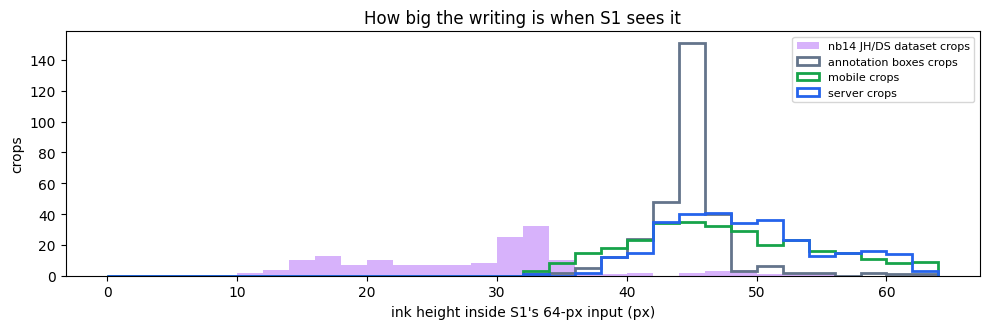

In [12]:
lk = R[R.kind != 'unmatched_prediction']
nb14 = json.loads((A / 'claude_margin_diagnostic_20261109/boxes_final.json').read_text())
mg = []
for arm in (MOB, SRV, GT):
    s = lk[lk.arm == arm]
    mg.append({'crops': da.SHORT[arm] + (' (app)' if arm == MOB else ''), 'n': len(s),
               'kept-height median': s.kept_fraction.median(), 'large margin (<=0.60)': (s.kept_fraction <= .6).mean(),
               'tight (>=0.85)': (s.kept_fraction >= .85).mean(), 'ink px in S1 input p5': s.ink_px_in_reader.quantile(.05),
               'ink px median': s.ink_px_in_reader.median(), 'ink px p95': s.ink_px_in_reader.quantile(.95),
               'ink touches top/bottom': int(s.ink_touches_top_bottom.sum())})
kh = np.array([b['kept_h'] for b in nb14]); fill = np.array([(b['ink'][3] - b['ink'][1]) / b['h'] for b in nb14])
mg.append({'crops': 'notebook 14: JH/DS dataset crops (original)', 'n': len(nb14), 'kept-height median': float(np.median(kh)),
           'large margin (<=0.60)': float((kh <= .6).mean()), 'tight (>=0.85)': float((kh >= .85).mean()),
           'ink px in S1 input p5': float(np.quantile(64 * fill, .05)), 'ink px median': float(np.median(64 * fill)),
           'ink px p95': float(np.quantile(64 * fill, .95)), 'ink touches top/bottom': None})
MG = pd.DataFrame(mg).set_index('crops'); display(MG.round(3))
fig, ax = plt.subplots(figsize=(10, 3.4))
bins = np.arange(0, 66, 2)
ax.hist(64 * fill, bins, alpha=.45, label='nb14 JH/DS dataset crops', color='#a855f7')
for arm, col in ((GT, '#64748b'), (MOB, '#16a34a'), (SRV, '#2563eb')):
    ax.hist(lk[lk.arm == arm].ink_px_in_reader, bins, histtype='step', lw=2, label=da.SHORT[arm] + ' crops', color=col)
ax.set_xlabel("ink height inside S1's 64-px input (px)"); ax.set_ylabel('crops'); ax.legend(fontsize=8); ax.set_title('How big the writing is when S1 sees it')
plt.tight_layout(); plt.show()

regions  chars  errors  mean_line_CER  corpus_CER
arm                 ink_touches_top_bottom                                                   
PP-OCRv5_mobile_det False                       227   1753     108         0.0662      0.0616
                    True                         71   1918      82         0.0462      0.0428
PP-OCRv5_server_det False                       207   1434     101         0.0738      0.0704
                    True                         93   2257      96         0.0466      0.0425

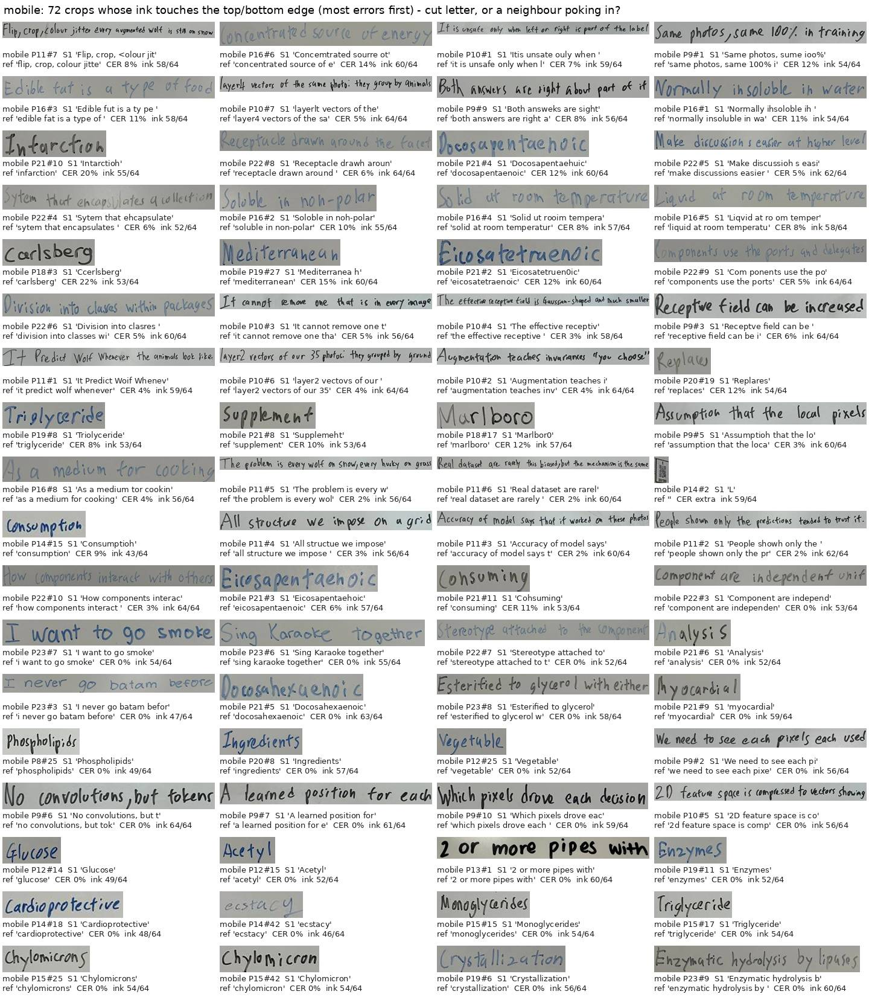

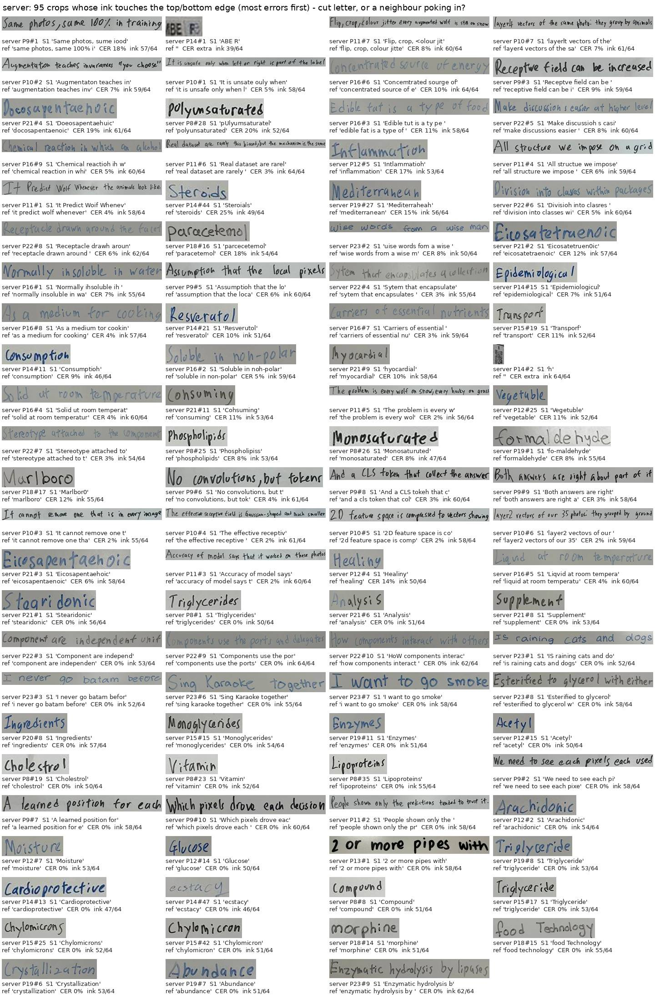

In [13]:
# Does a flagged crop (ink touching top/bottom edge) read worse? One-to-one regions only.
oo = R[(R.kind == 'one_to_one') & R.arm.isin([MOB, SRV])].copy()
oo['CER'] = oo.component_errors / oo.component_chars
display(oo.groupby(['arm', 'ink_touches_top_bottom']).agg(regions=('CER', 'size'), chars=('component_chars', 'sum'),
        errors=('component_errors', 'sum'), mean_line_CER=('CER', 'mean')).assign(corpus_CER=lambda d: d.errors / d.chars).round(4))
for arm in (MOB, SRV):
    flagged = R[(R.arm == arm) & R.ink_touches_top_bottom].sort_values('component_errors', ascending=False)
    p = da.gallery(flagged.to_dict('records'), arms, VIS / f'flag_touch_{da.SHORT[arm]}.jpg',
                   f'{da.SHORT[arm]}: {len(flagged)} crops whose ink touches the top/bottom edge (most errors first) - cut letter, or a neighbour poking in?')
    display(IPImage(filename=str(p), width=1100))

## 6 · Where the two detectors disagree

Below are the targets where the two detectors handled the text differently: a different component type, or a different number of errors. Each row shows the annotation-box crop, then mobile's region(s), then server's.

66 of 300 targets differ between detectors (server fewer errors on 30, more on 35)


,photo_id,gt_id,reference,mobile_kind,mobile_text,mobile_component_errors,server_kind,server_text,server_component_errors
2,8,8.1.3,compound,one_to_one,compuund,1,one_to_one,compound,0
4,8,8.1.5,esterified,one_to_one,esterified,0,one_to_one,esterifiel,1
11,8,8.1.12,membrane,merge_candidate,membrane lipoproteins,0,one_to_one,membrune,1
21,8,8.2.9,phospholipids,one_to_one,phospholipids,0,one_to_one,phospholipiss,1
24,8,8.2.12,lipoproteins,merge_candidate,membrane lipoproteins,0,one_to_one,lipoproteins,0
...,...,...,...,...,...,...,...,...,...
285,22,22.2.4,make discussions easier at higher level,one_to_one,make discussioh s easier at higher level,2,one_to_one,make discussioh s casier at higher level,3
287,22,22.4.1,stereotype attached to the component,one_to_one,stereotype attached to the component,0,one_to_one,stereotype attached to the componemt,1
289,22,22.6.1,components use the ports and delegates,one_to_one,com ponents use the ports and delegates.,2,one_to_one,components use the ports and delegates,0
290,22,22.7.1,how components interact with others,one_to_one,how components interact with ofhers,1,one_to_one,how components interact with others,0


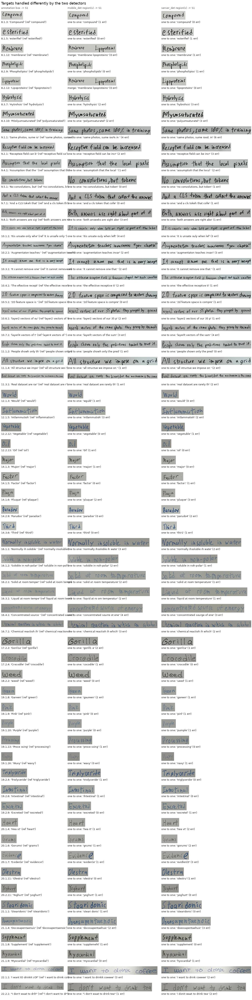

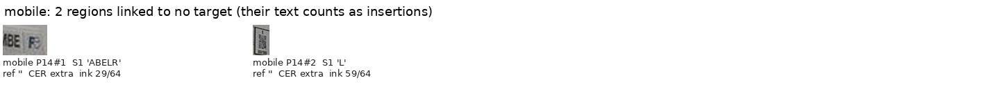

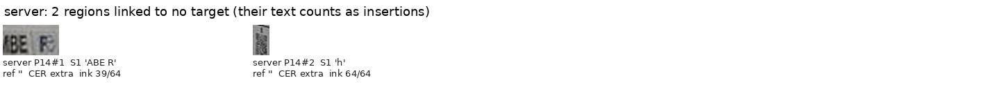

In [14]:
dis = T[(T.mobile_kind != T.server_kind) | (T.mobile_component_errors != T.server_component_errors)]
print(f'{len(dis)} of {len(T)} targets differ between detectors '
      f'(server fewer errors on {(dis.server_component_errors < dis.mobile_component_errors).sum()}, more on {(dis.server_component_errors > dis.mobile_component_errors).sum()})')
display(dis[['photo_id', 'gt_id', 'reference', 'mobile_kind', 'mobile_text', 'mobile_component_errors', 'server_kind', 'server_text', 'server_component_errors']])
if len(dis):
    p = da.pair_gallery(dis.to_dict('records'), arms, VIS / 'disagreements.jpg', 'Targets handled differently by the two detectors')
    display(IPImage(filename=str(p), width=1200))
for arm in (MOB, SRV):
    ex = R[(R.arm == arm) & (R.kind == 'unmatched_prediction')]
    if len(ex):
        p = da.gallery(ex.to_dict('records'), arms, VIS / f'extra_{da.SHORT[arm]}.jpg', f'{da.SHORT[arm]}: {len(ex)} regions linked to no target (their text counts as insertions)')
        display(IPImage(filename=str(p), width=1100))

## 7 · Photo-by-photo visual review (all 16 photos)

**Overlays** (2 × 2 per photo): mobile raw and after grouping (top), server raw and after grouping (bottom). The number on each box is its index in the app's reading order: the order S1's lines are joined in the page text.

| colour | meaning |
|---|---|
| green | one-to-one |
| purple | merge |
| blue | split |
| orange | many-to-many |
| **red box** | region linked to no target |
| **red filled quad** | missed target |
| thin grey | annotation quads |

**Crop strips** (one per detector): each region as it was cut (left), and the exact S1 input on the right. The input is resized to 64 px high and padded to width 1024; mid-grey is padding. A blue bar marks the ink's height. The line under each crop shows S1's text, the matched reference, the component CER, kept-height, ink pixels and any flags.

### Photo 8 — page CER mobile 0.740, server 0.757; regions 38 vs 39; targets 39

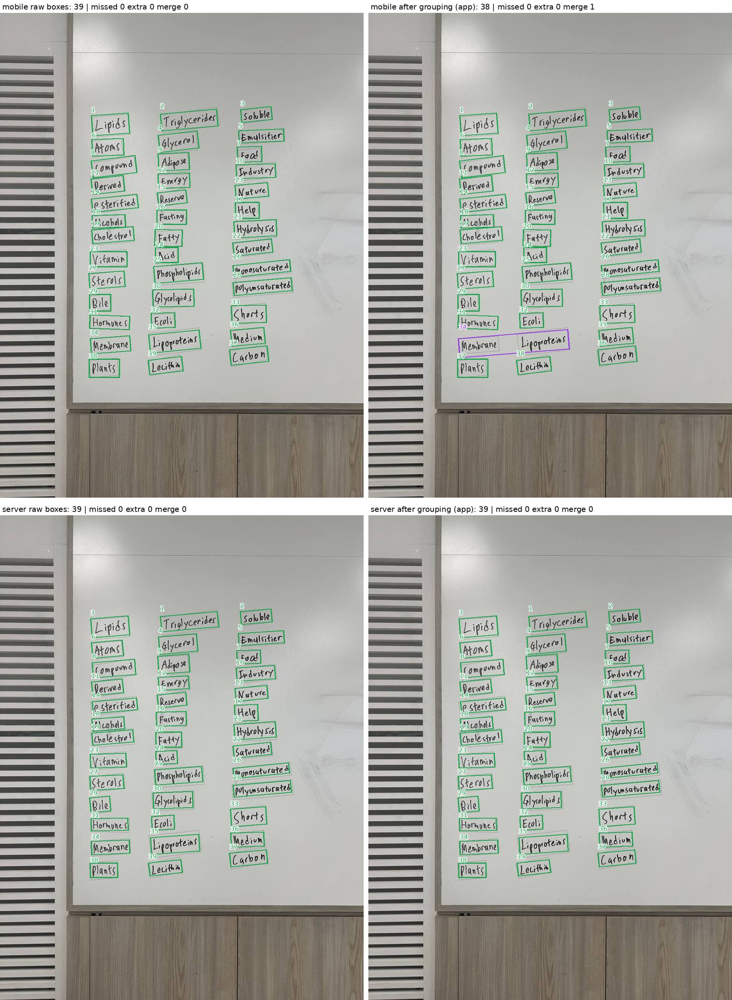

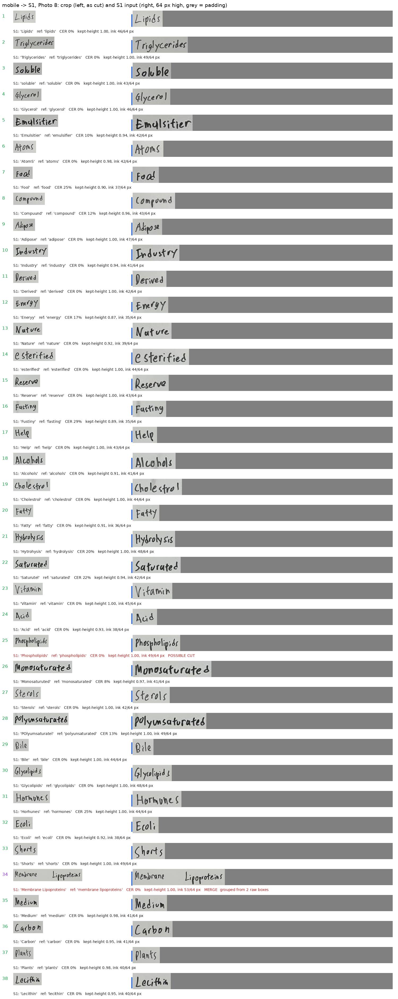

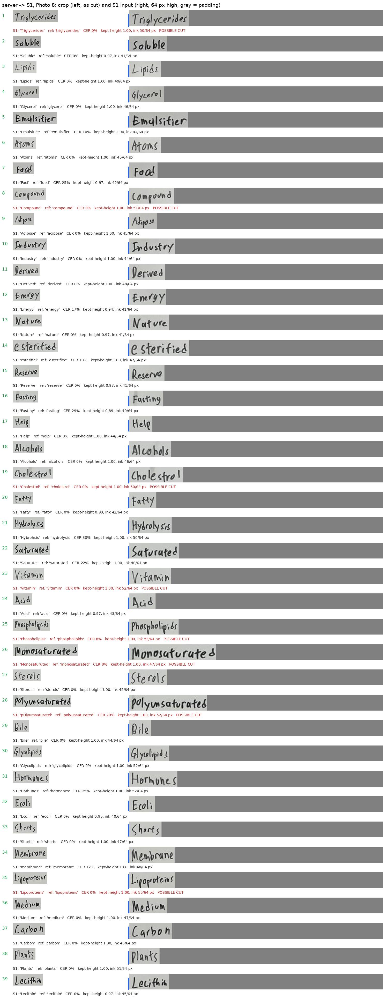

### Photo 9 — page CER mobile 0.030, server 0.042; regions 10 vs 10; targets 10

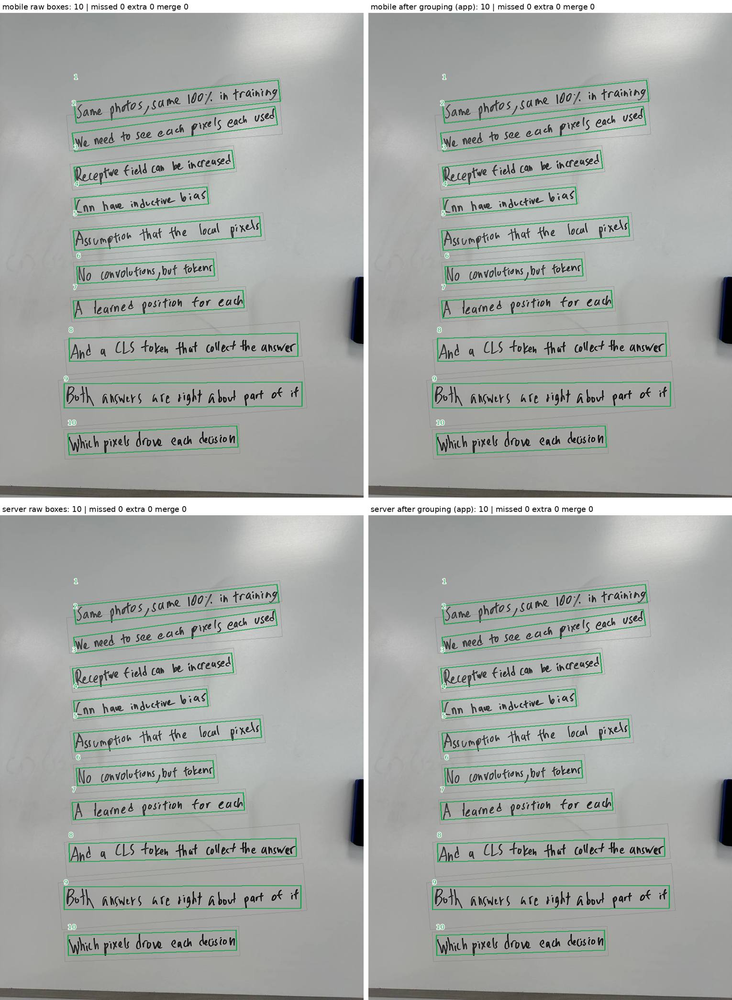

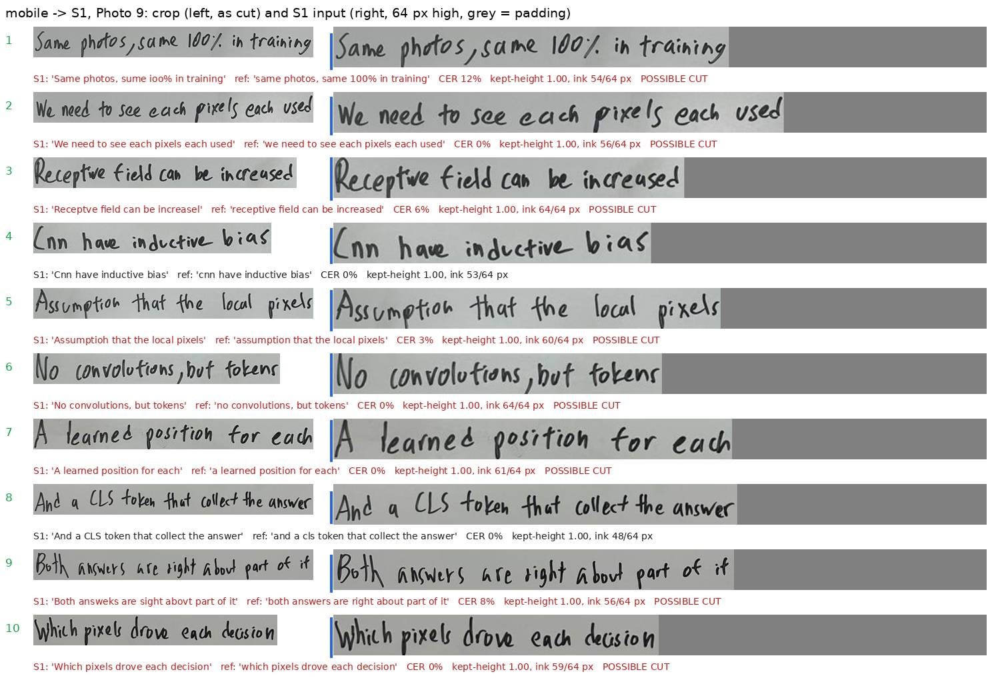

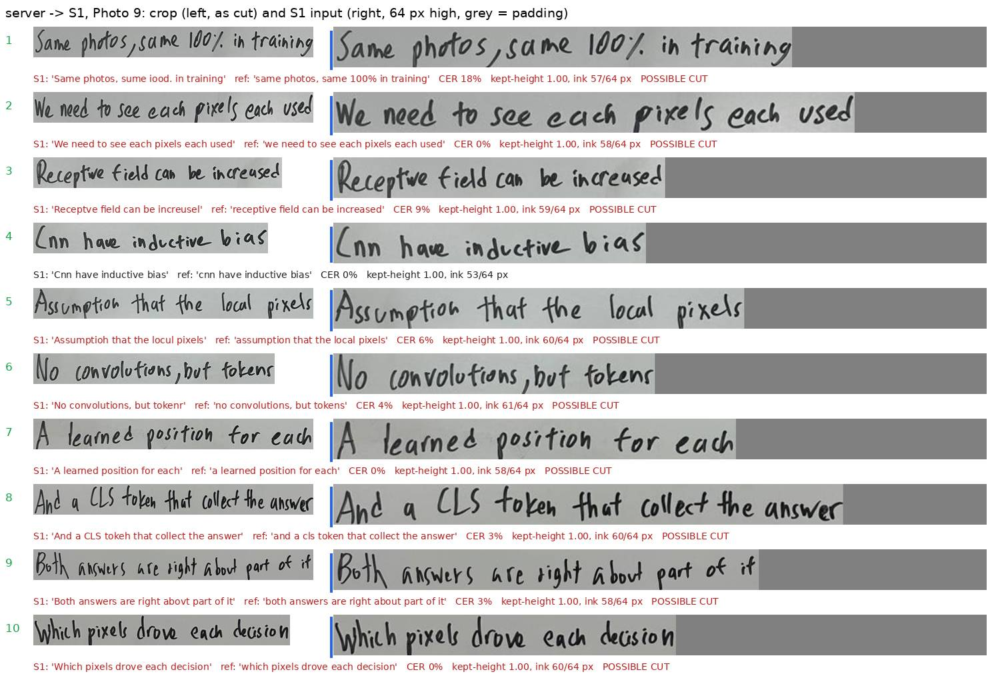

### Photo 10 — page CER mobile 0.040, server 0.037; regions 7 vs 7; targets 7

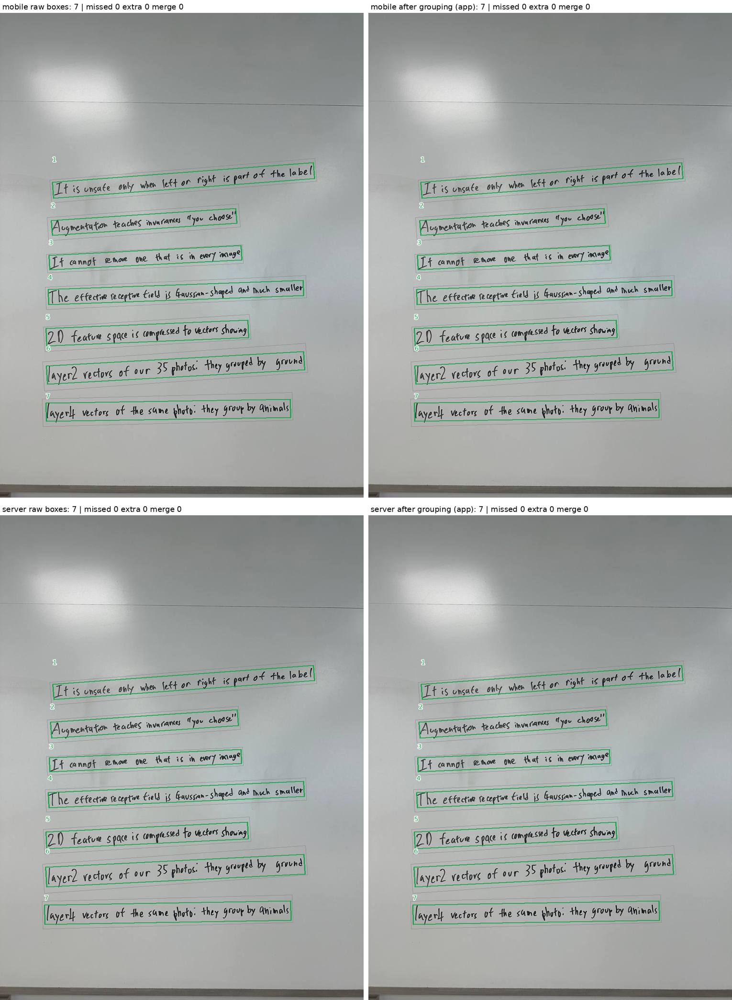

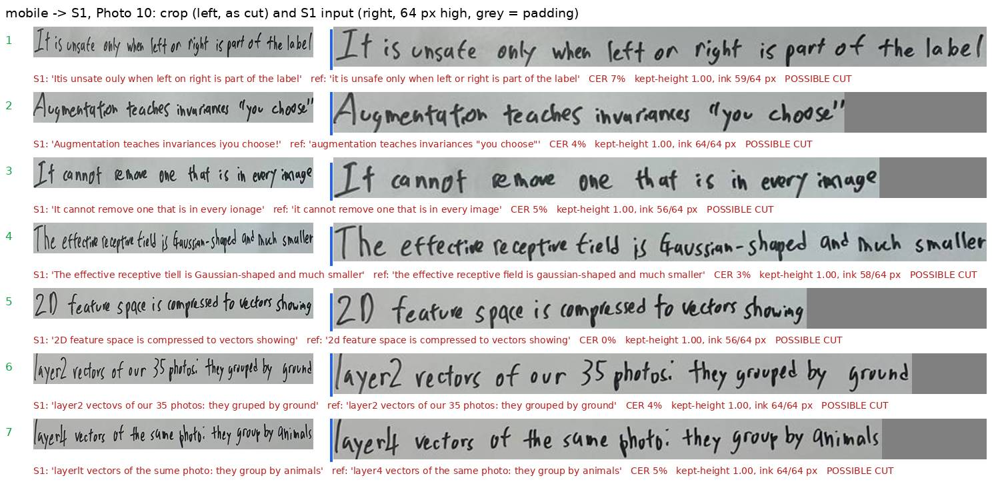

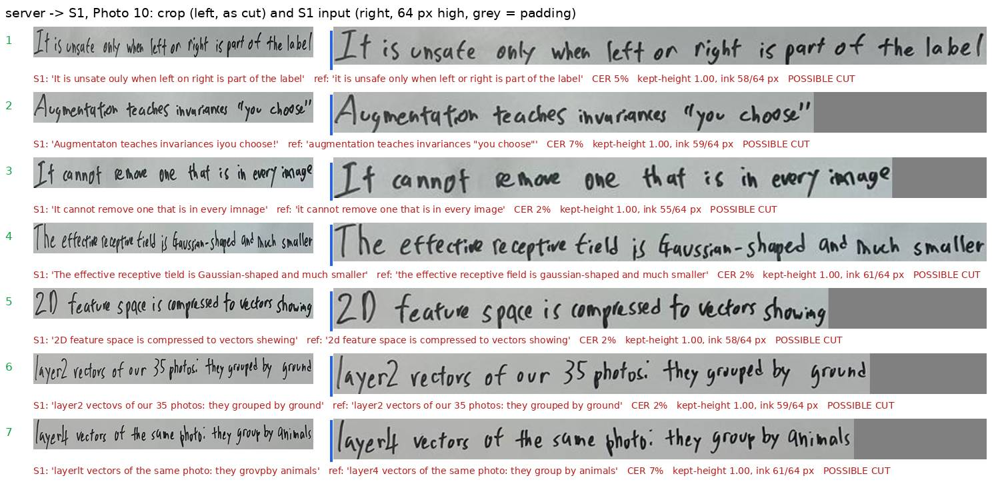

### Photo 11 — page CER mobile 0.032, server 0.035; regions 7 vs 7; targets 7

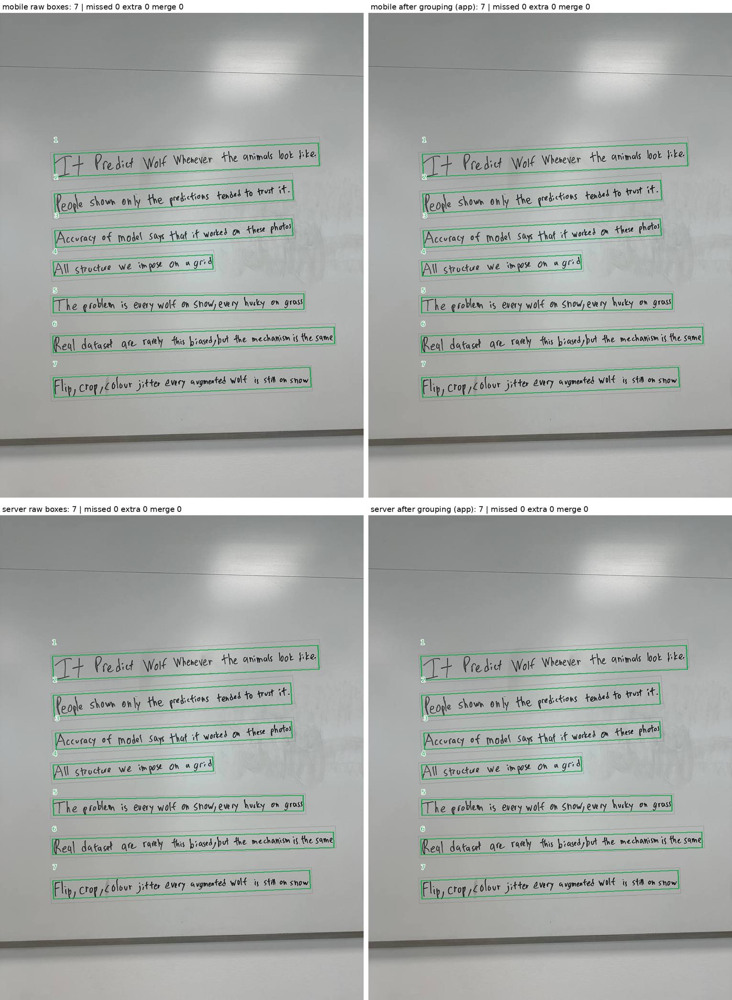

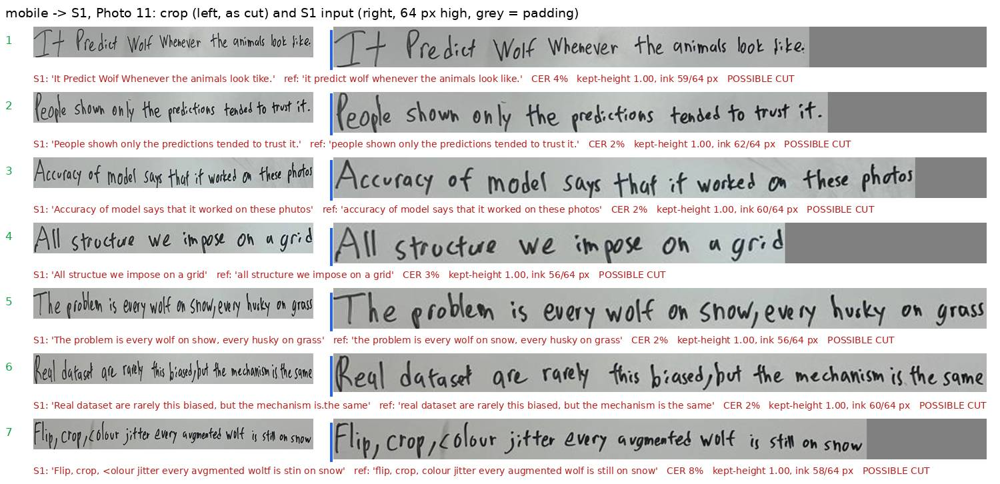

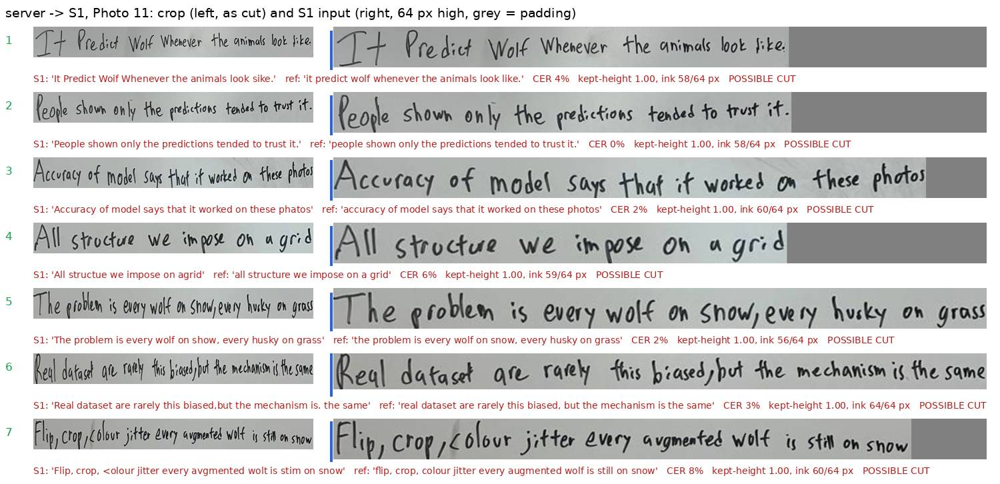

### Photo 12 — page CER mobile 0.050, server 0.040; regions 26 vs 26; targets 26

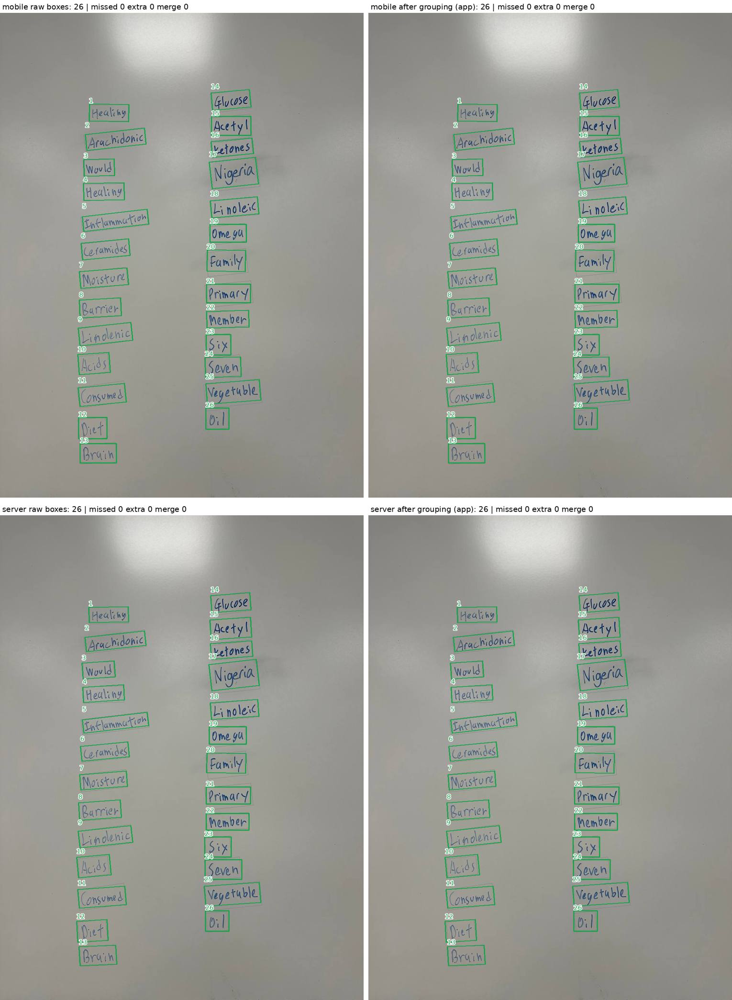

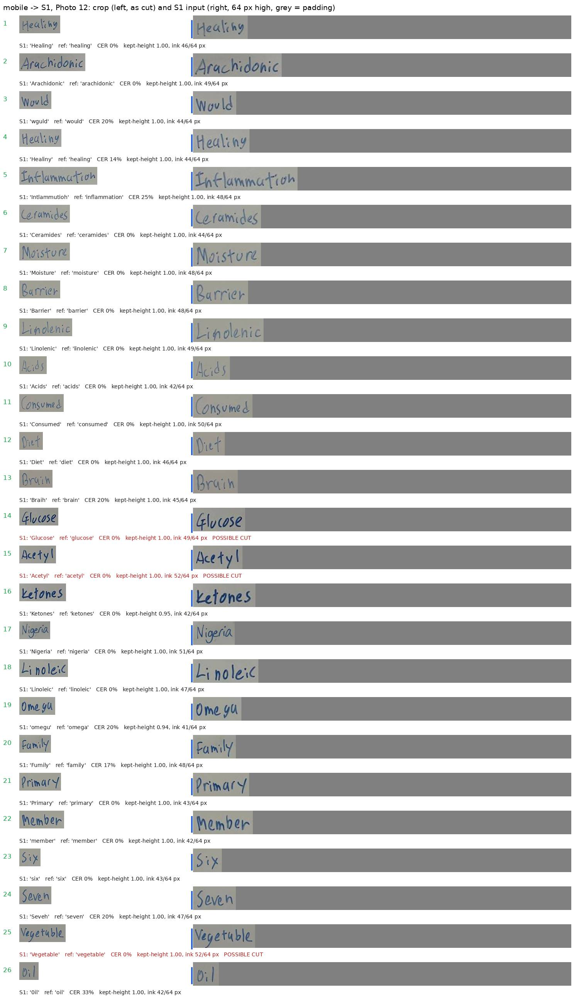

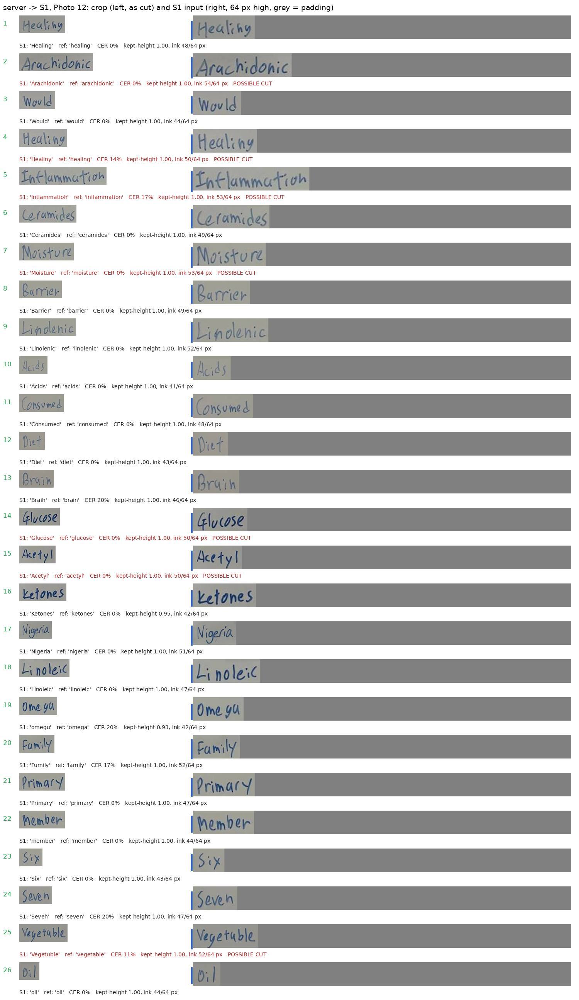

### Photo 13 — page CER mobile 0.081, server 0.081; regions 3 vs 3; targets 3

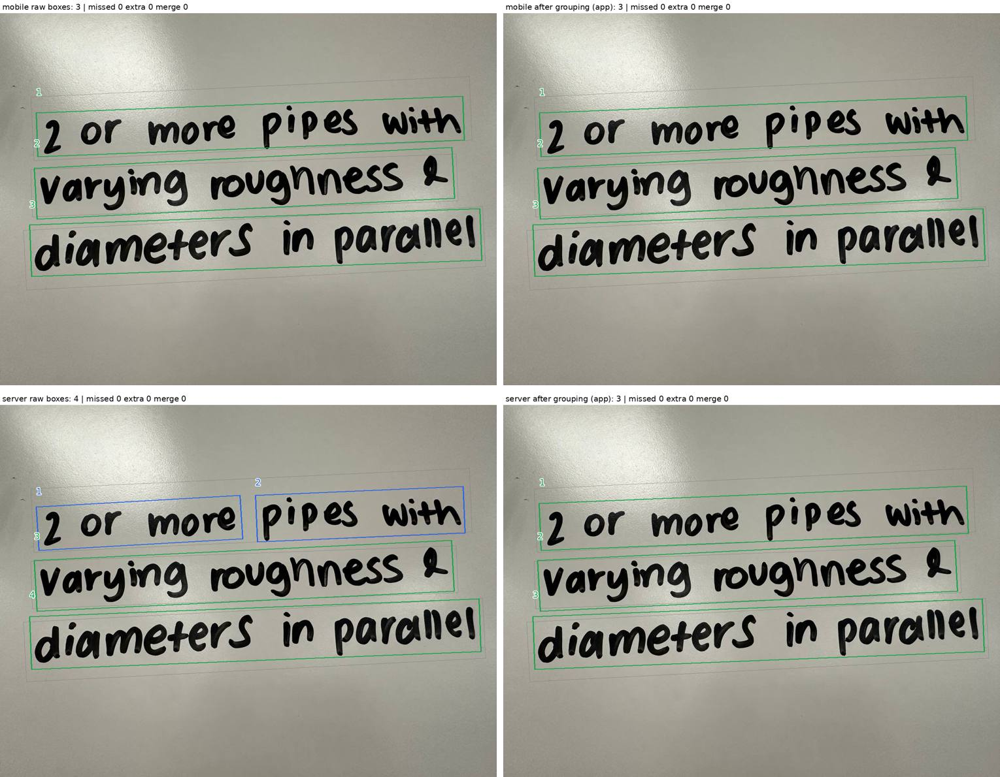

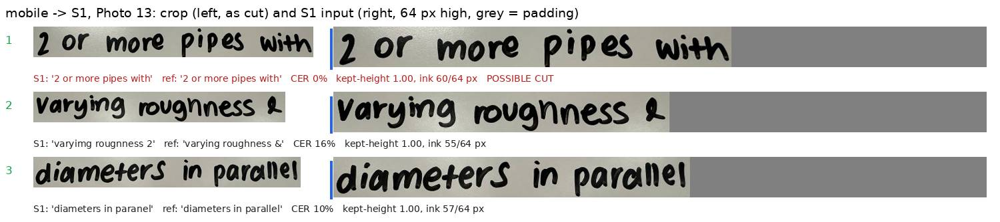

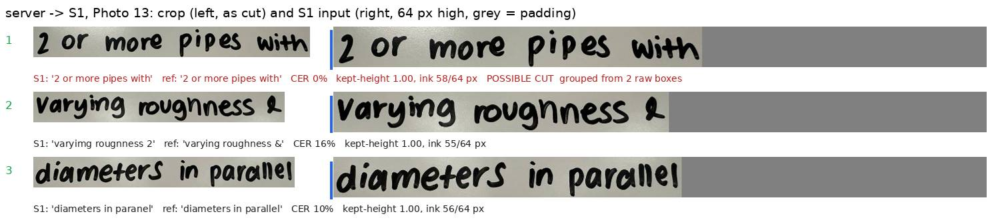

### Photo 14 — page CER mobile 0.729, server 0.507; regions 50 vs 50; targets 48

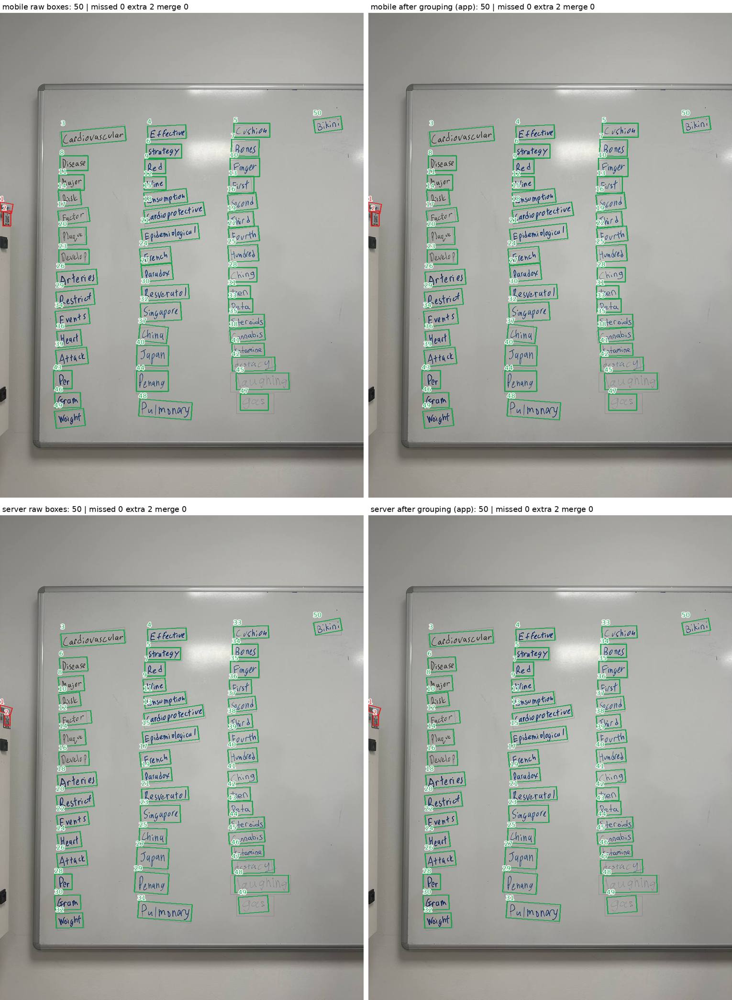

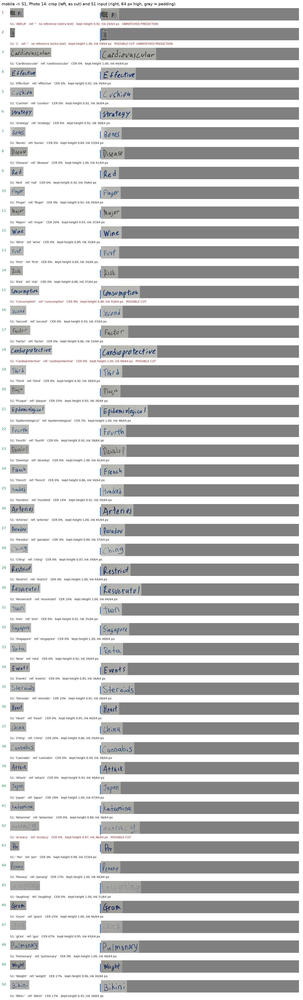

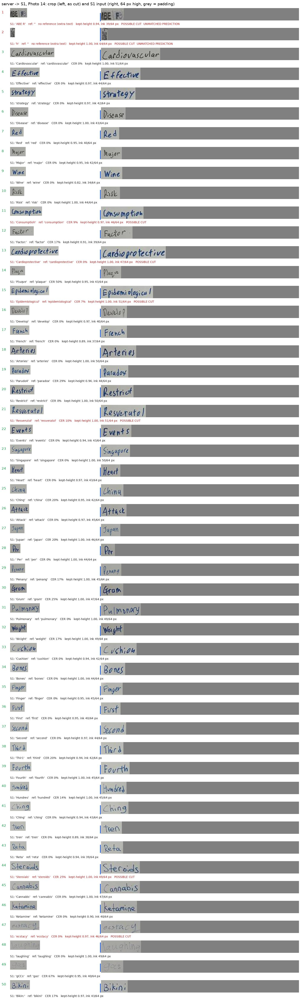

### Photo 15 — page CER mobile 0.736, server 0.742; regions 43 vs 43; targets 43

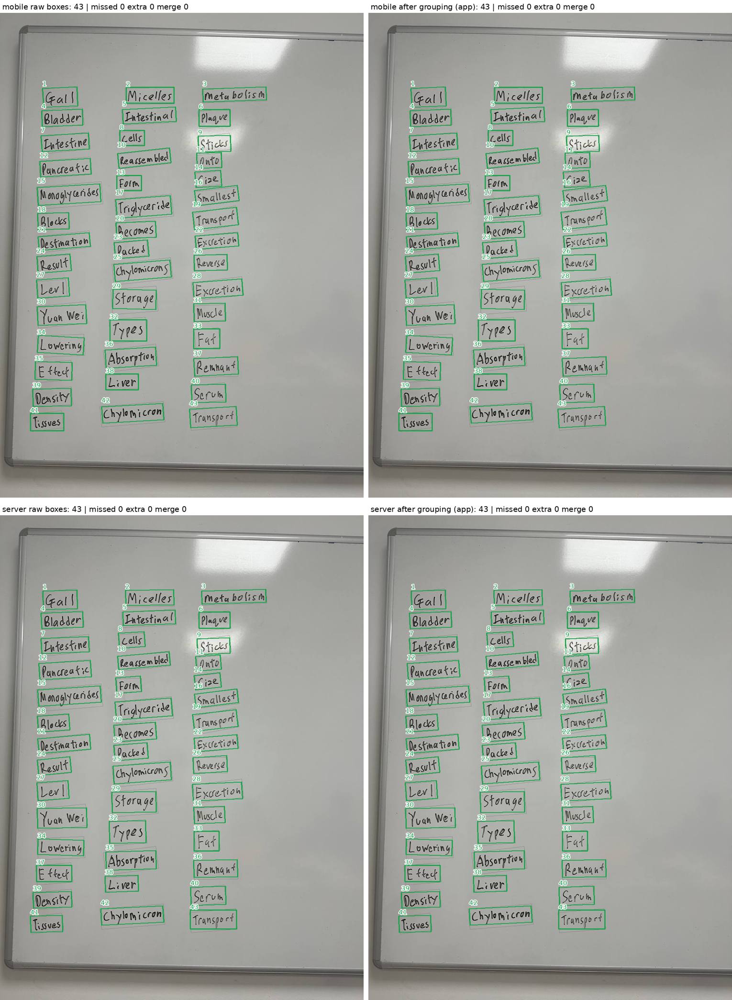

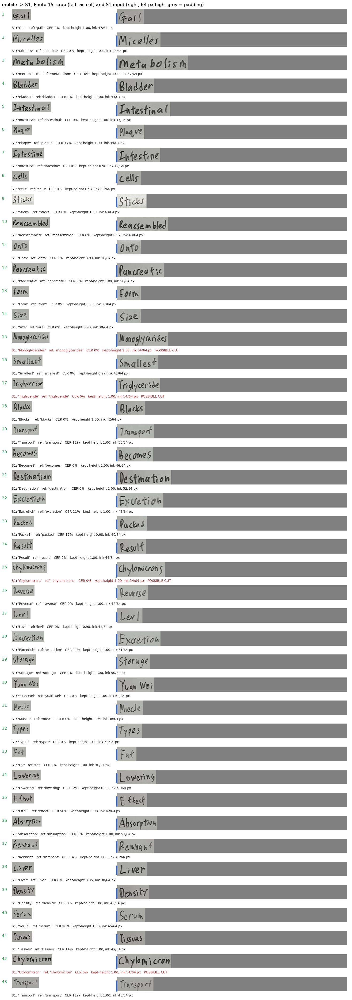

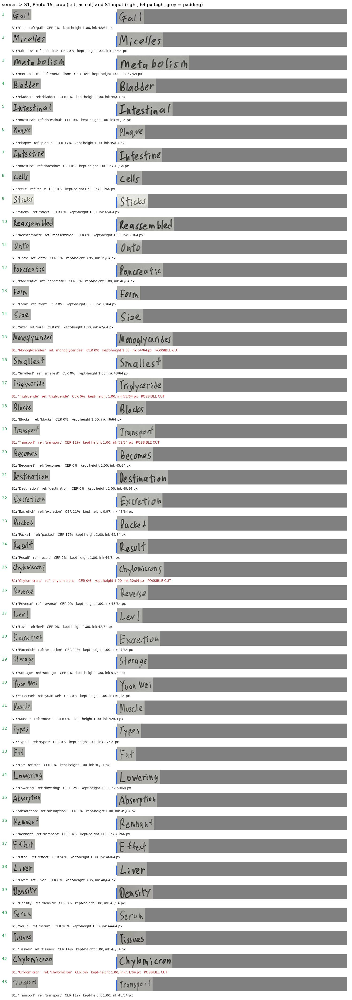

### Photo 16 — page CER mobile 0.083, server 0.059; regions 9 vs 9; targets 9

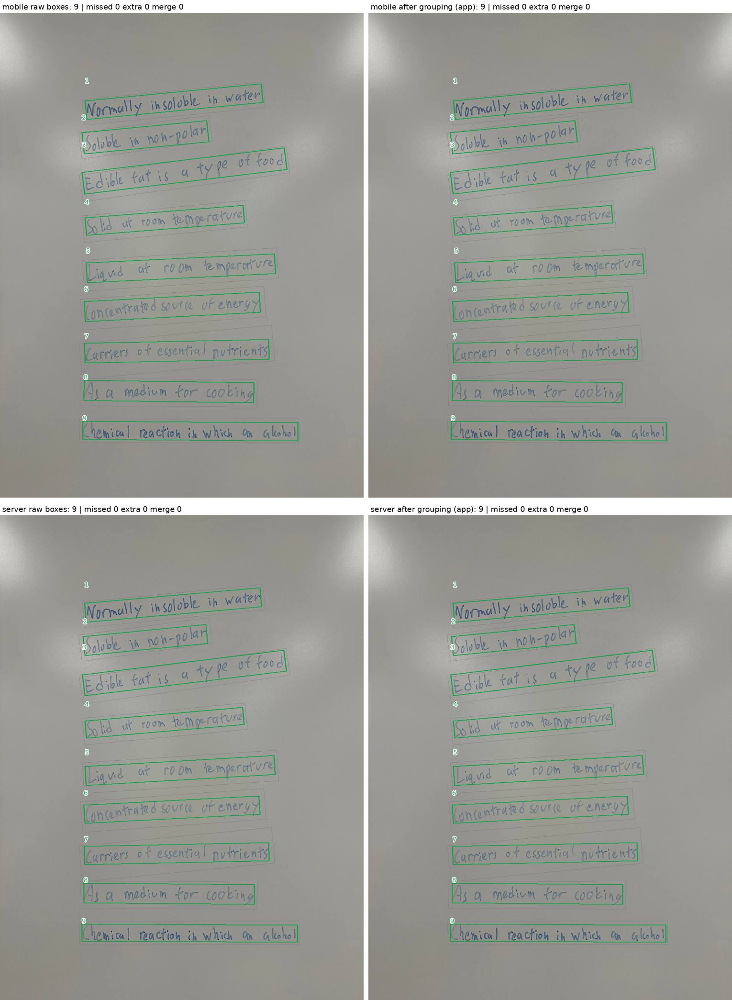

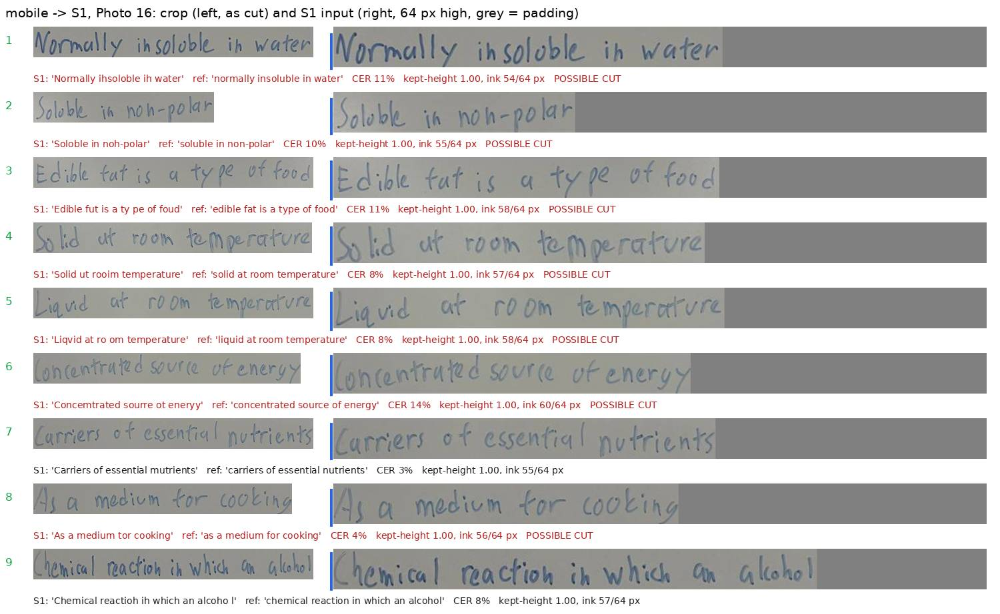

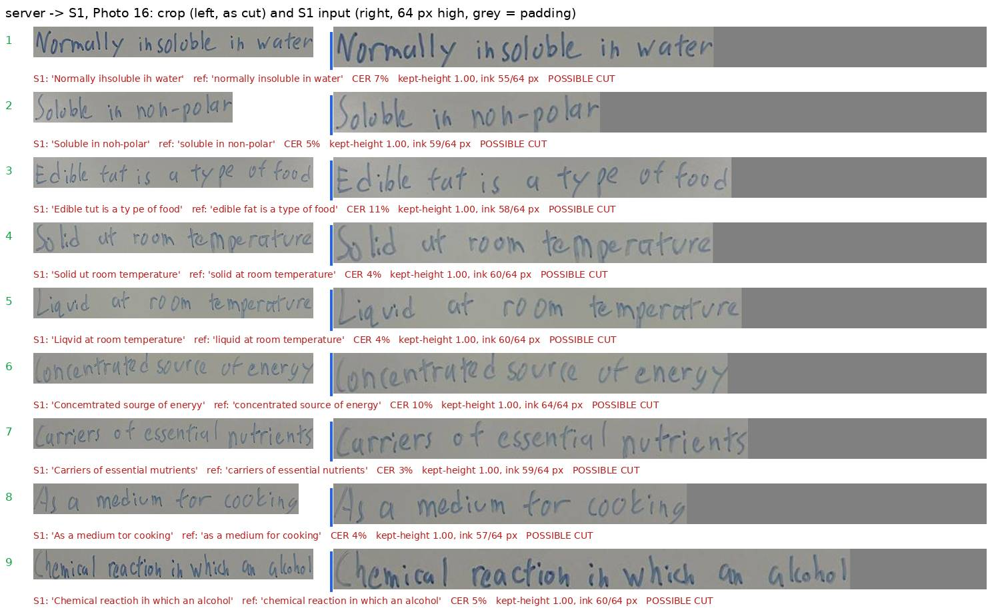

### Photo 17 — page CER mobile 0.118, server 0.078; regions 8 vs 8; targets 8

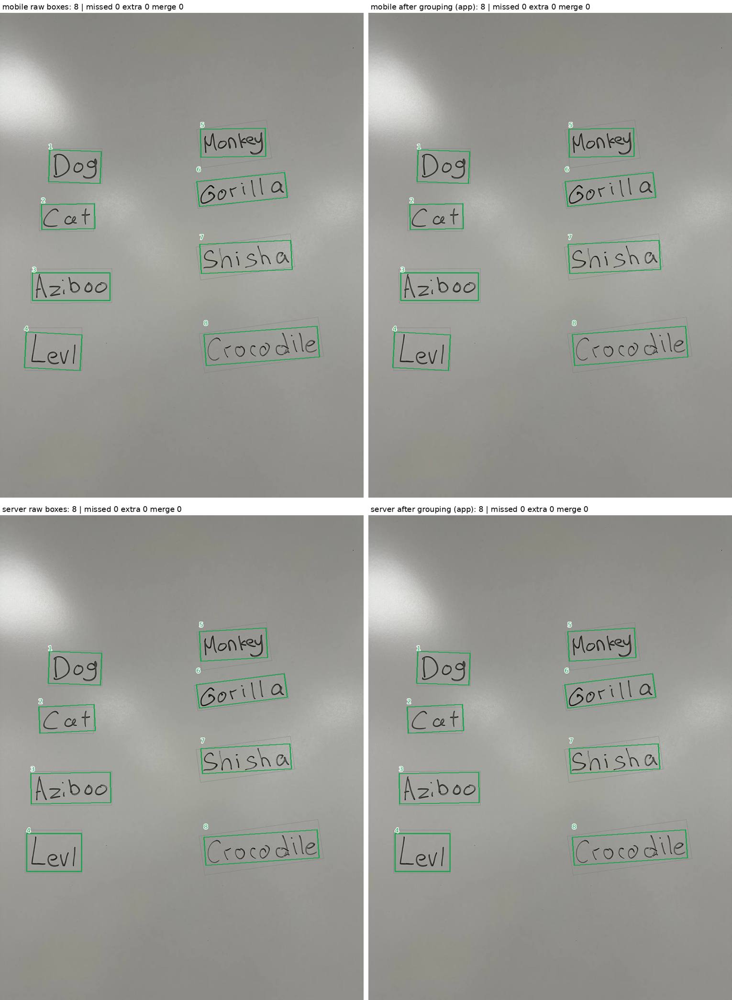

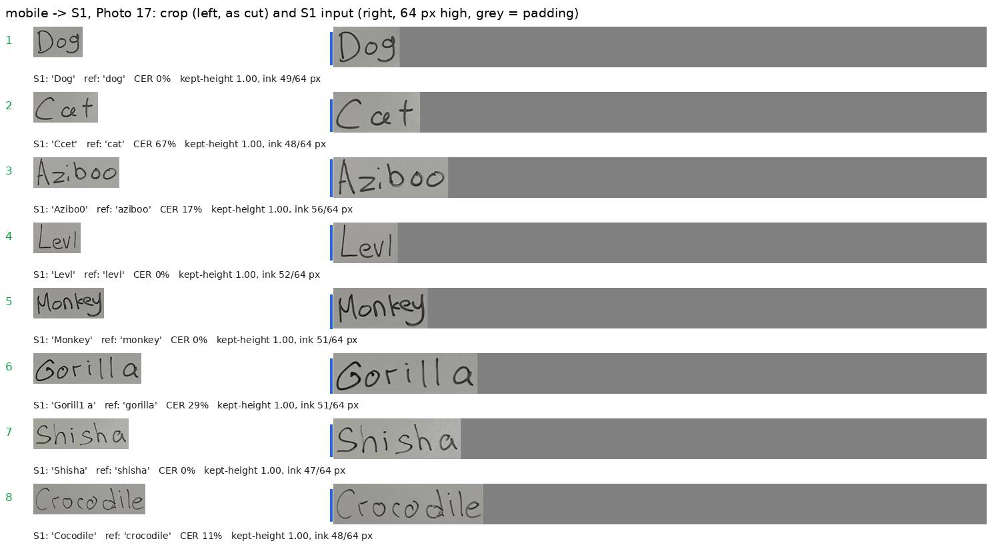

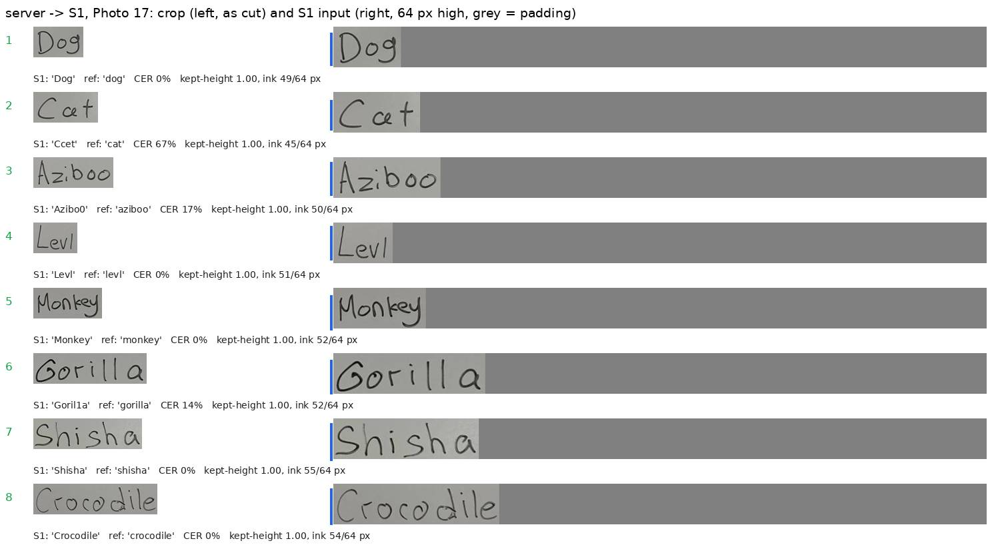

### Photo 18 — page CER mobile 0.057, server 0.064; regions 17 vs 17; targets 17

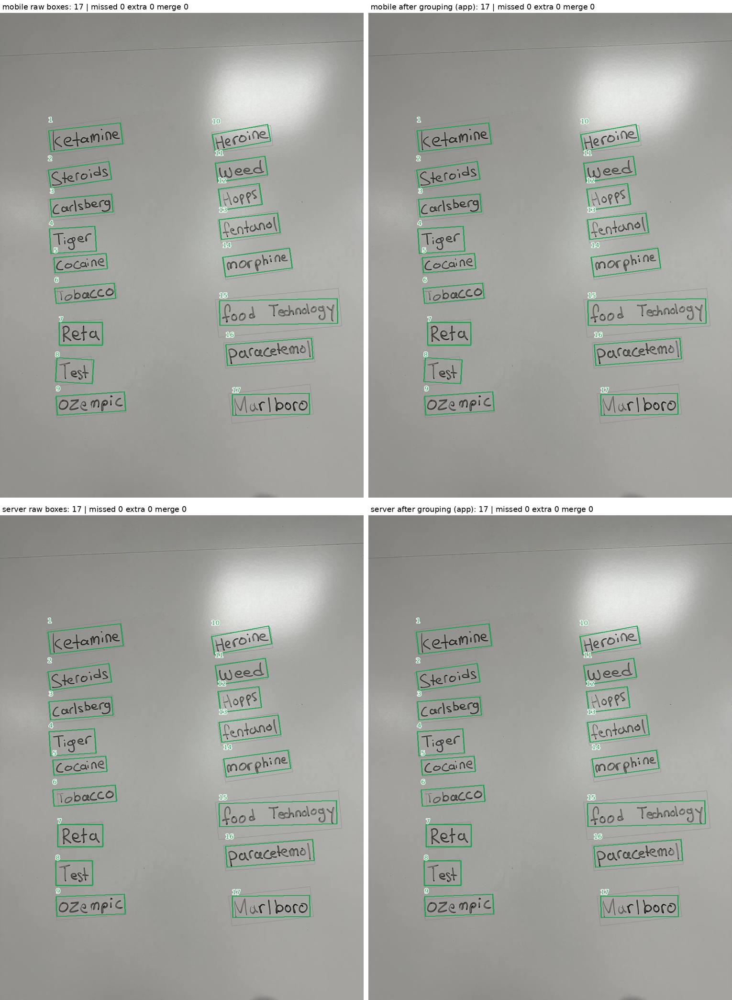

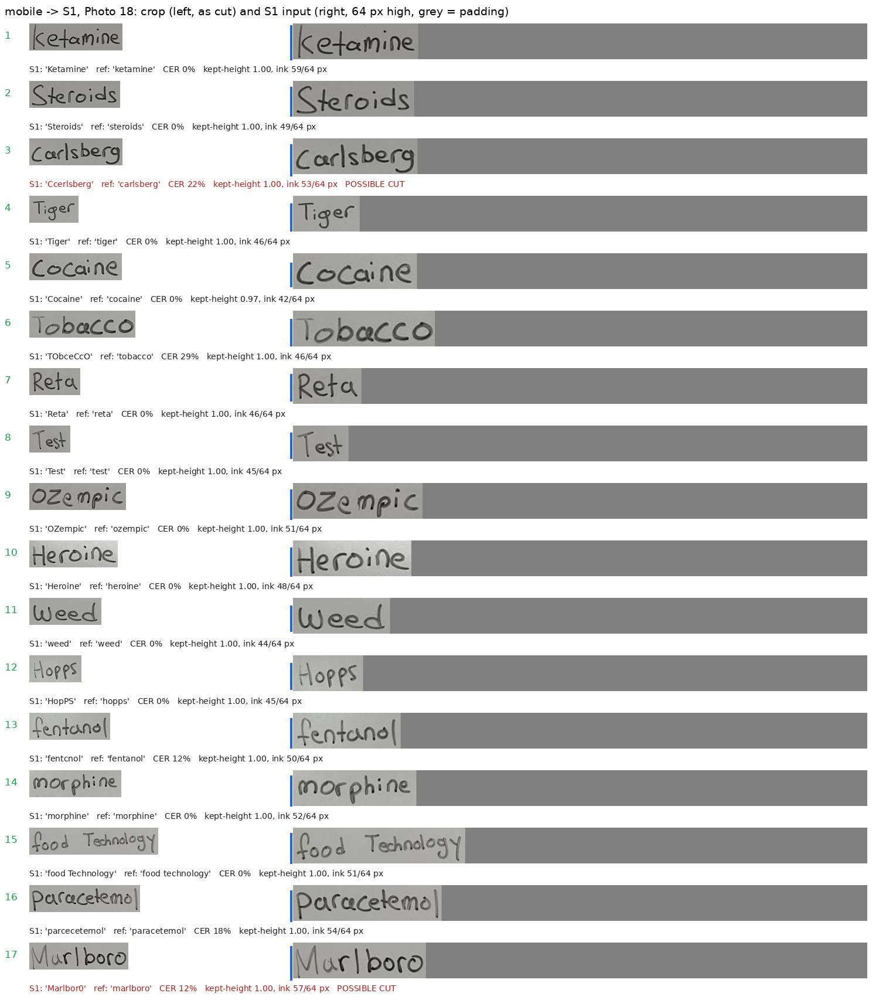

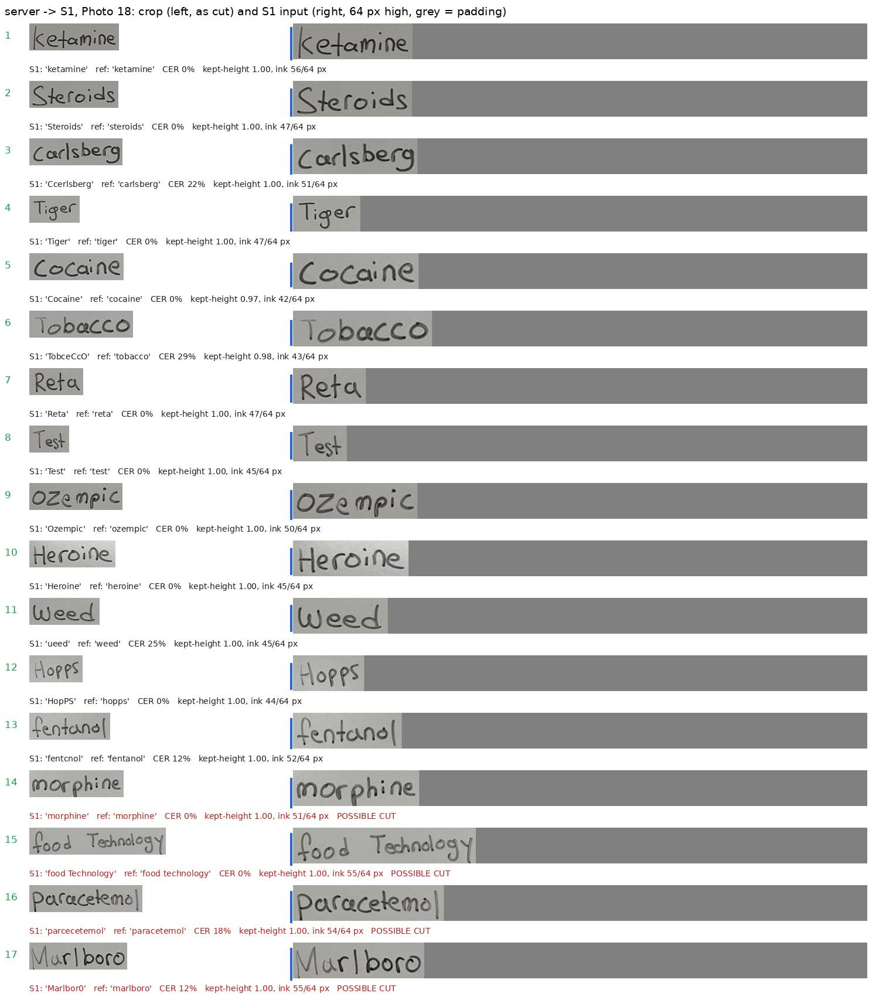

### Photo 19 — page CER mobile 0.738, server 0.730; regions 30 vs 30; targets 30

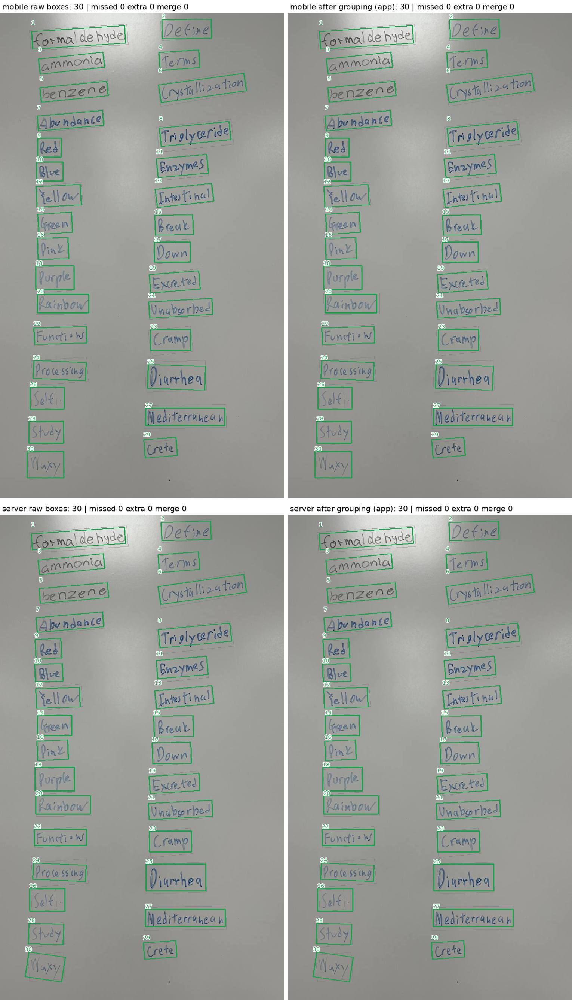

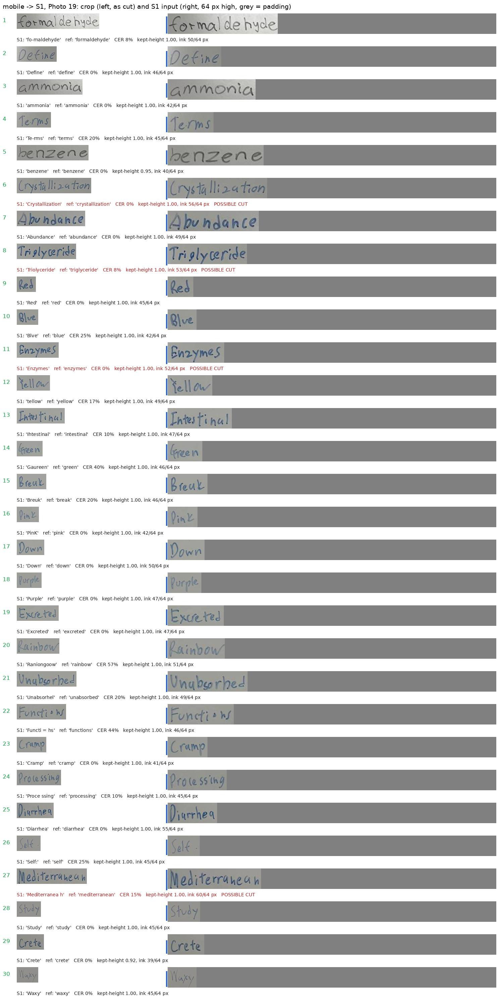

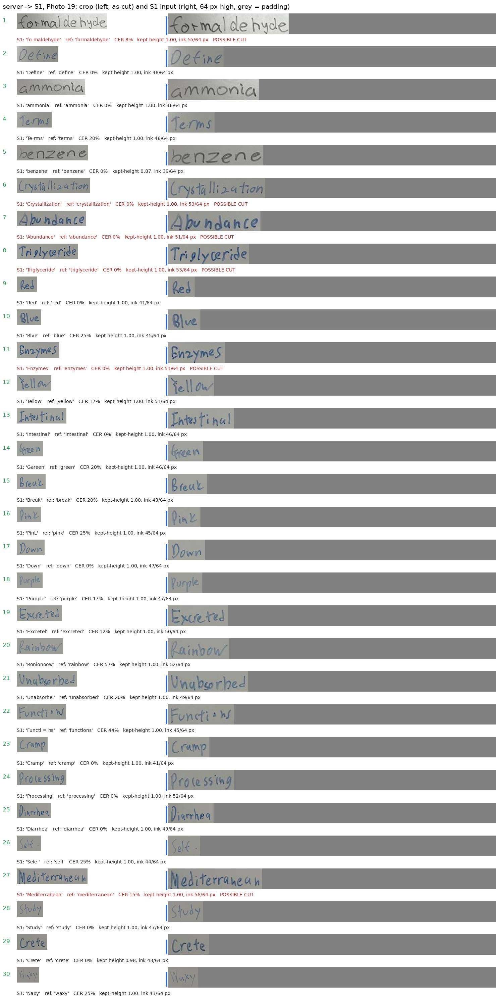

### Photo 20 — page CER mobile 0.047, server 0.071; regions 23 vs 23; targets 23

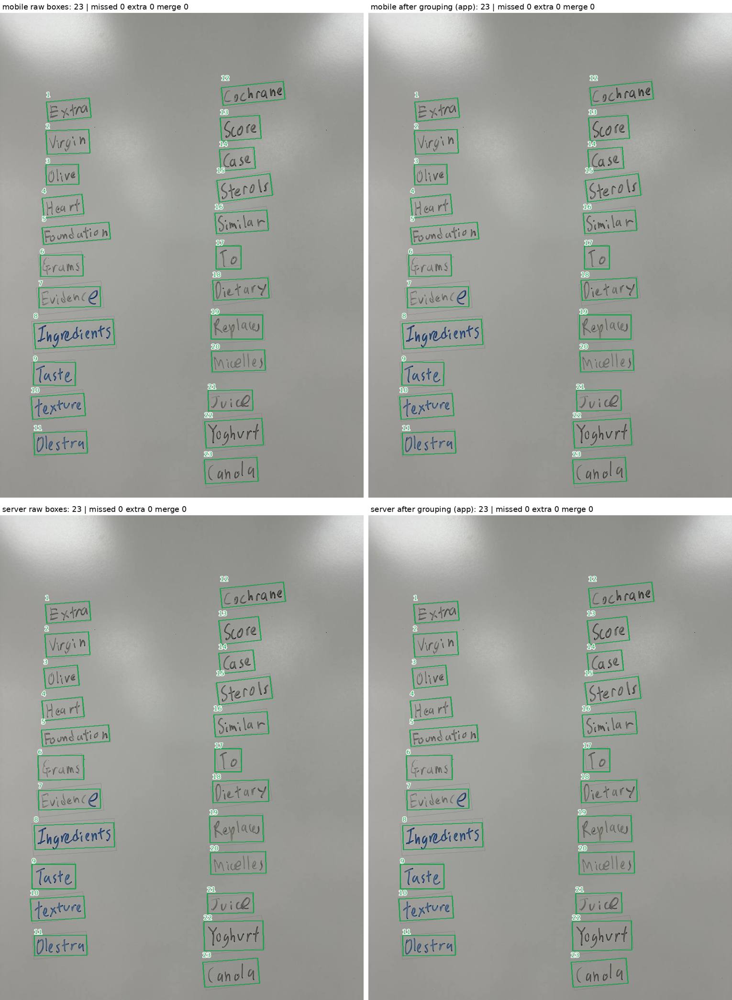

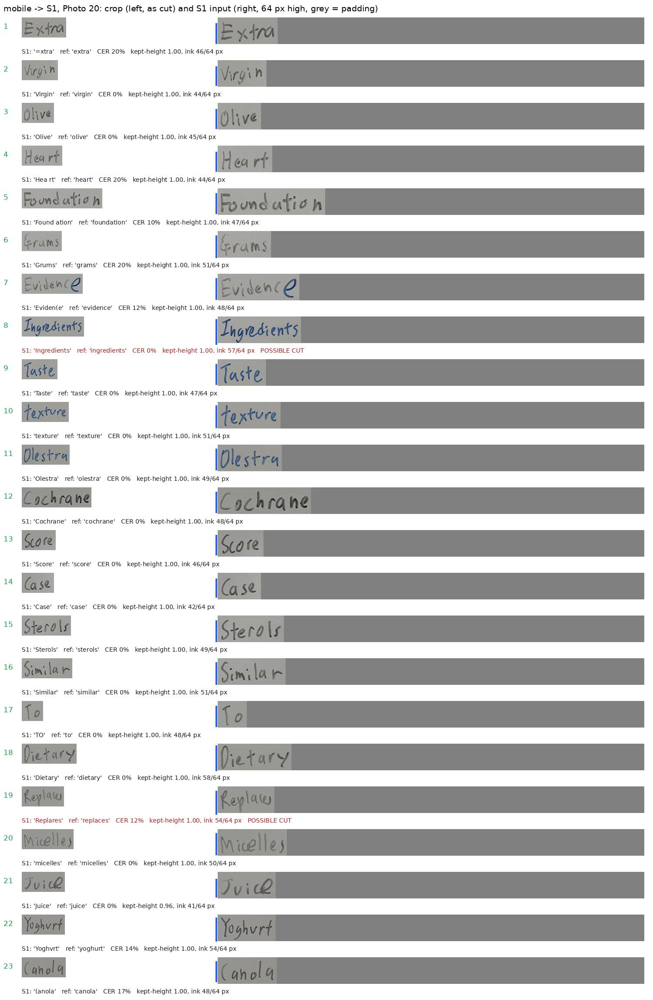

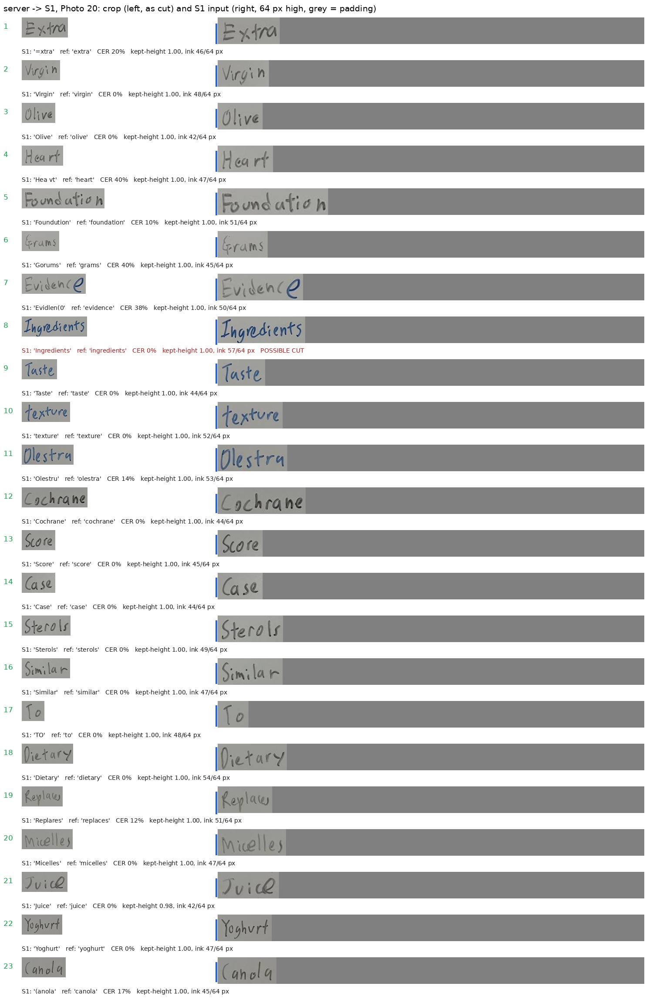

### Photo 21 — page CER mobile 0.073, server 0.073; regions 11 vs 11; targets 11

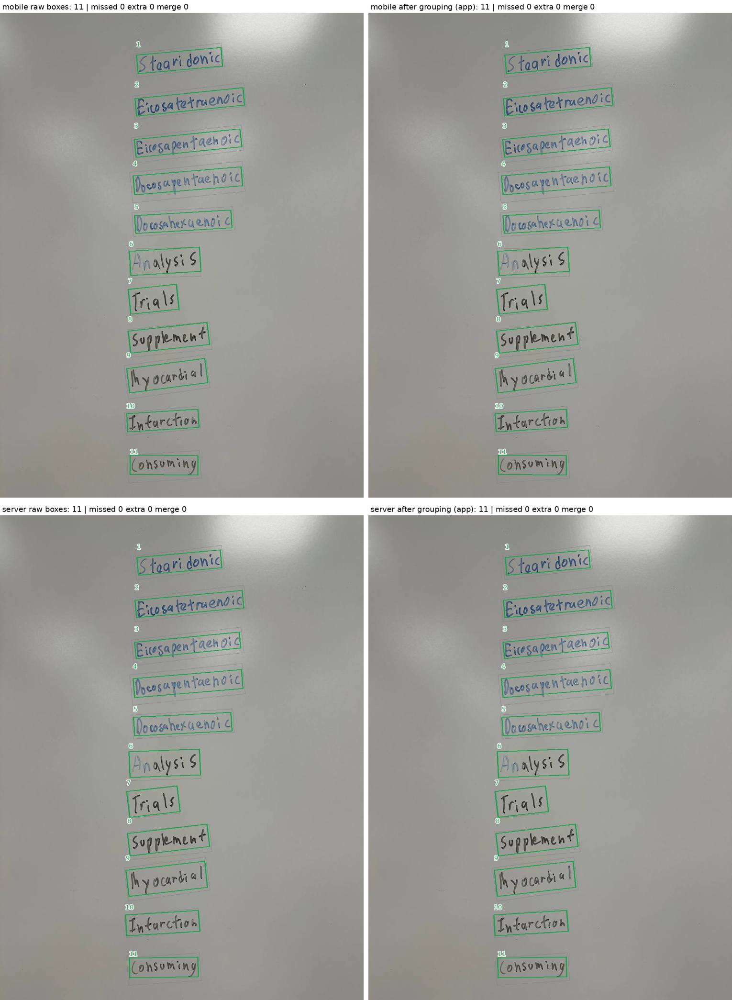

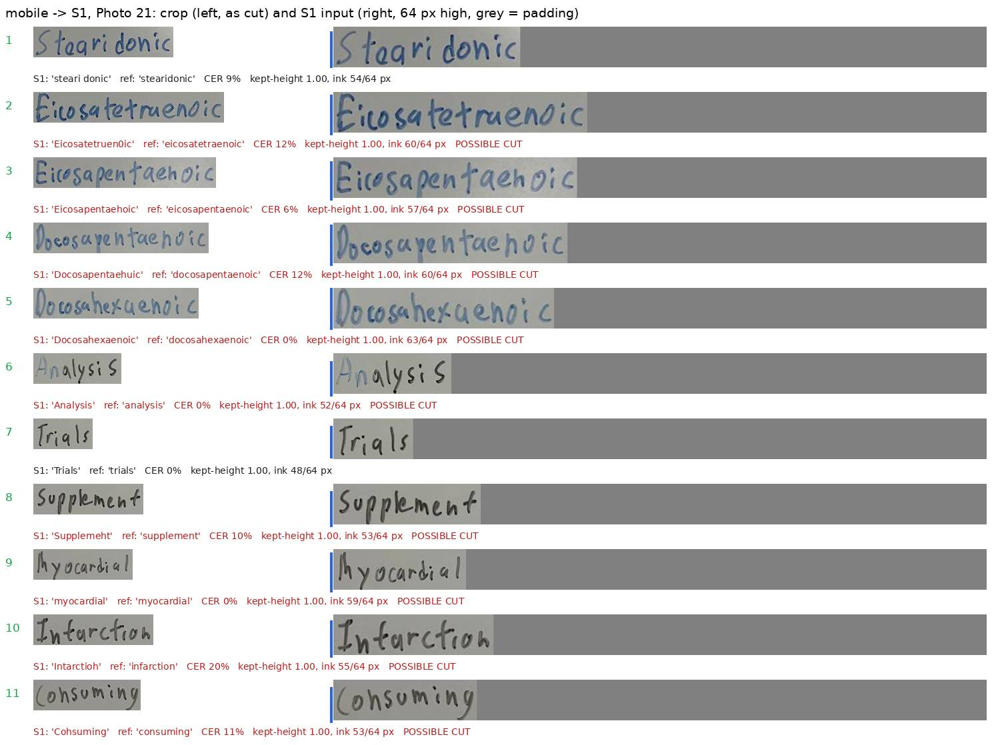

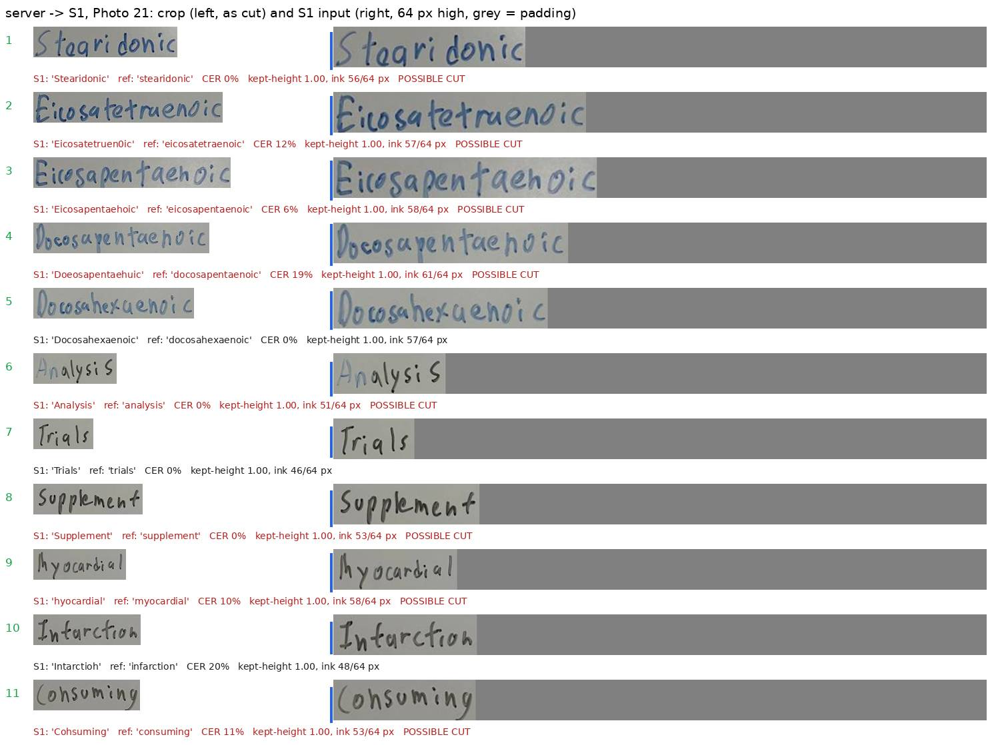

### Photo 22 — page CER mobile 0.044, server 0.038; regions 10 vs 10; targets 10

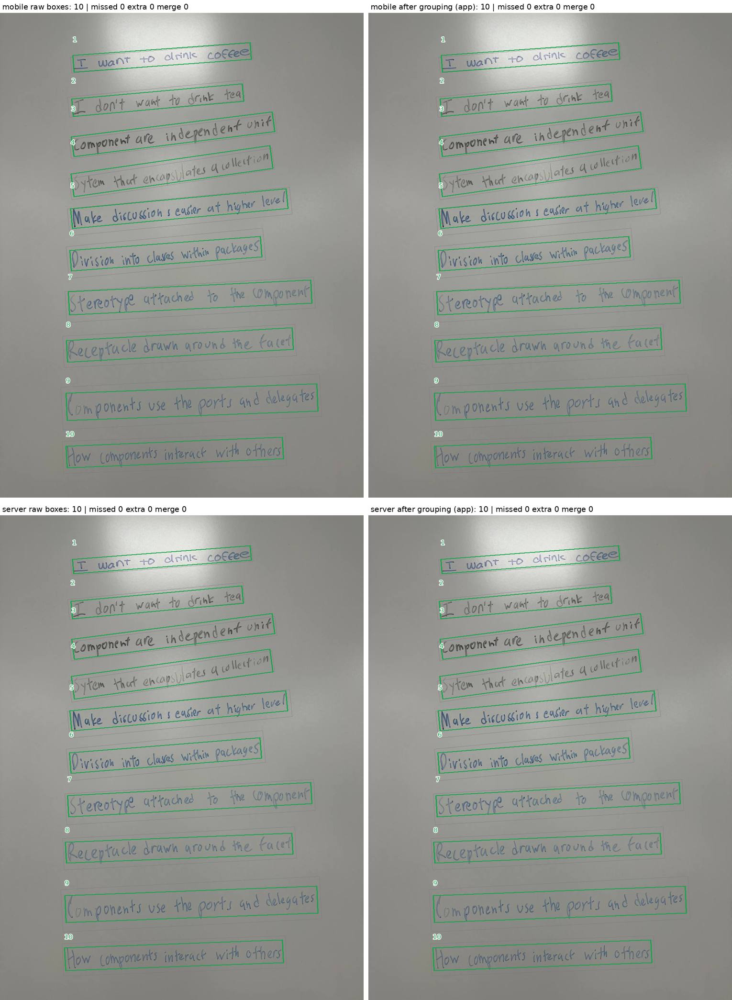

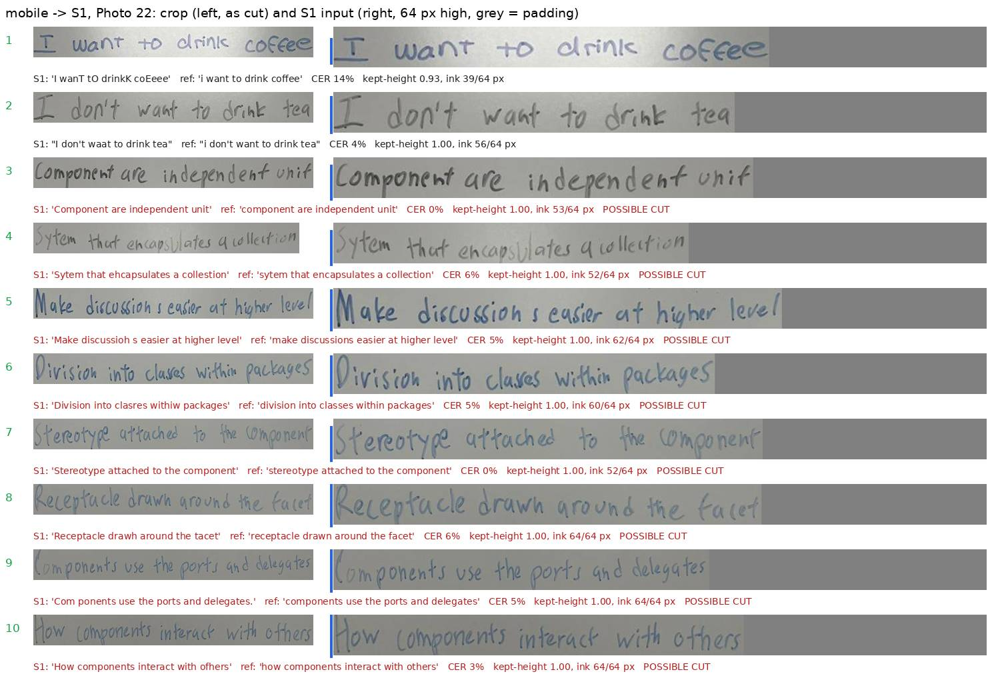

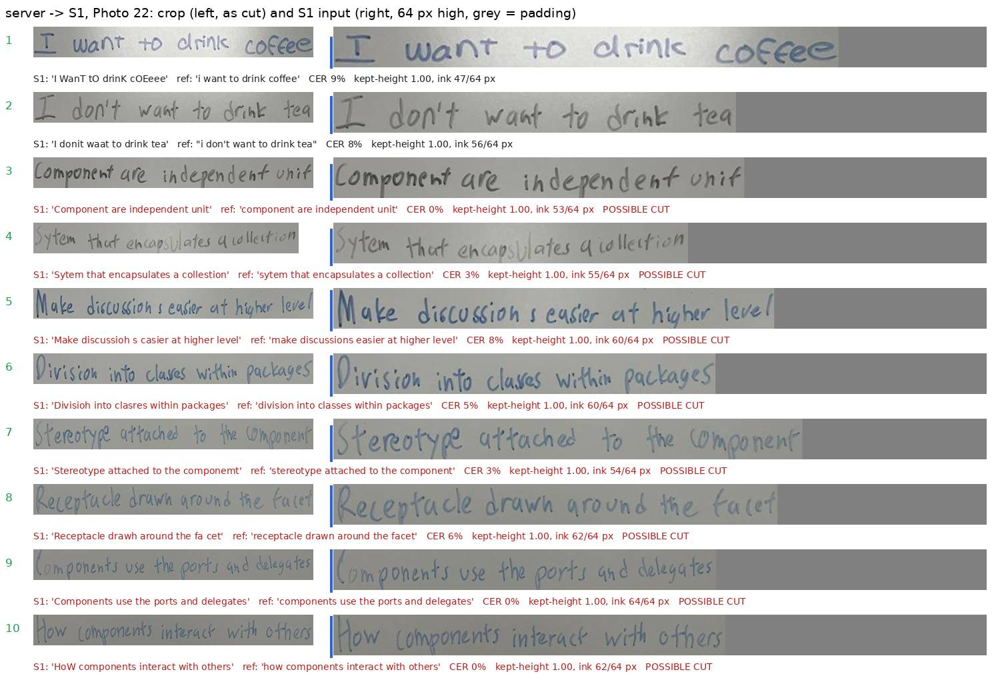

### Photo 23 — page CER mobile 0.005, server 0.014; regions 9 vs 9; targets 9

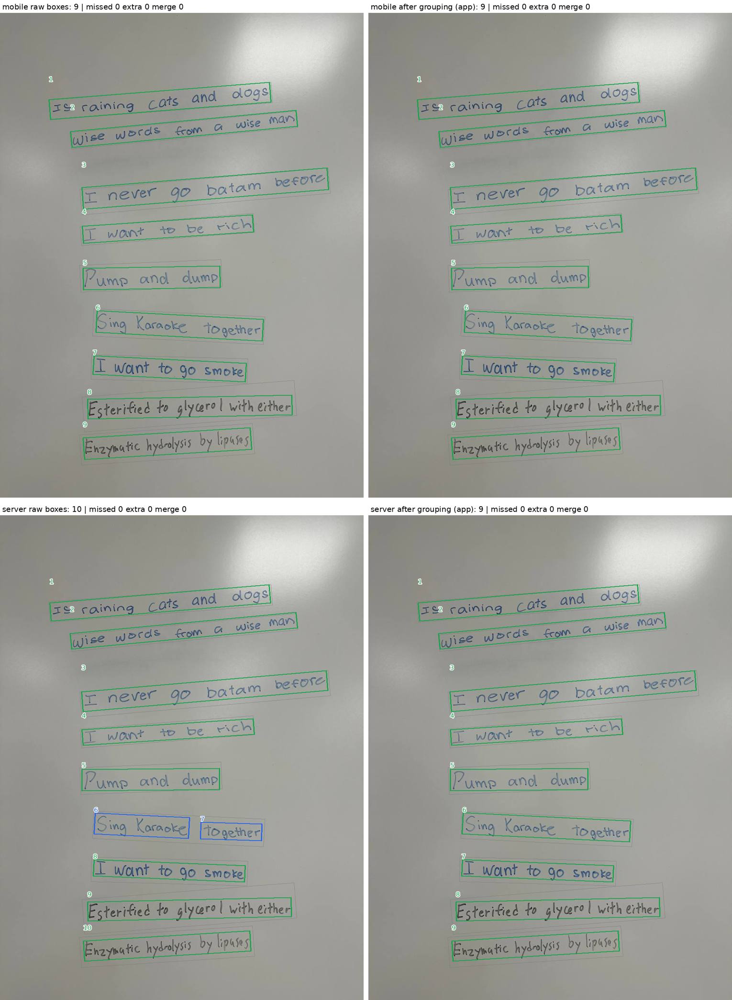

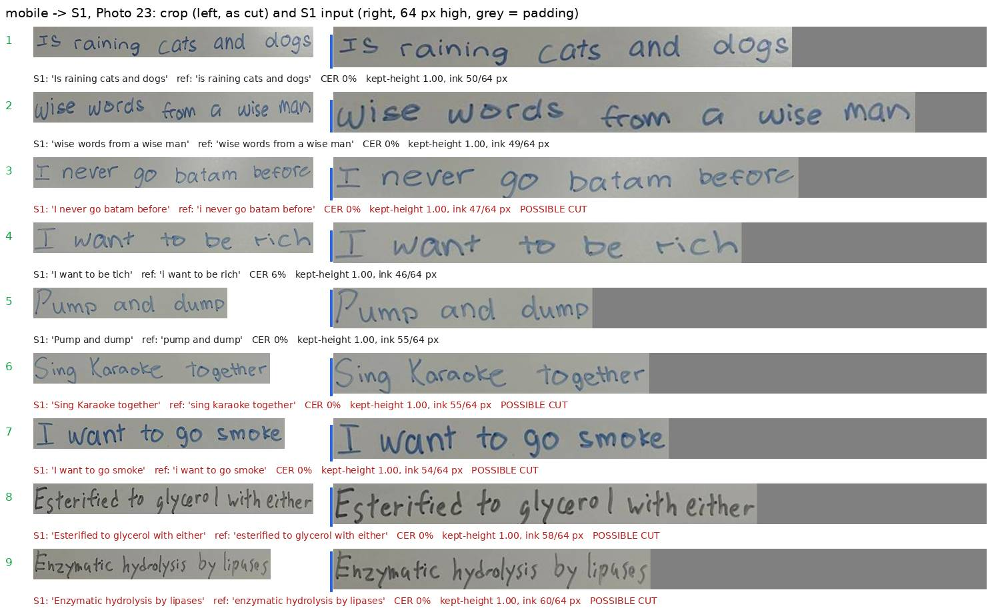

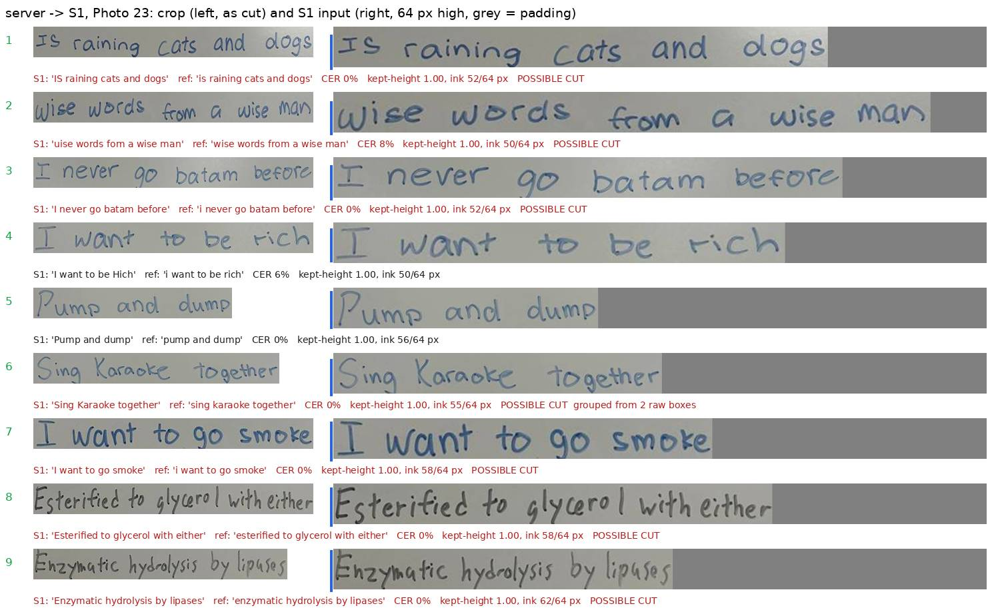

In [15]:
for pid in sorted(arms[MOB]['photos']):
    display(Markdown(f"### Photo {pid} — page CER mobile {ev[MOB][pid]['grouped']['page_errors']/ev[MOB][pid]['grouped']['chars']:.3f}, "
                     f"server {ev[SRV][pid]['grouped']['page_errors']/ev[SRV][pid]['grouped']['chars']:.3f}; "
                     f"regions {len(arms[MOB]['photos'][pid]['grouped'])} vs {len(arms[SRV]['photos'][pid]['grouped'])}; targets {len(ev[GT][pid]['grouped']['components'])}"))
    display(IPImage(filename=str(da.overlay_sheet(keys, arms, ev, pid, VIS / f'overlay_Photo_{pid}.jpg')), width=1150))
    for arm in (MOB, SRV):
        display(IPImage(filename=str(da.crop_strip(arms, R.to_dict('records'), arm, pid, VIS / f'strip_{da.SHORT[arm]}_Photo_{pid}.jpg')), width=1000))

## 8 · Answers against the pre-declared rules

In [16]:
cm, cs = da.corpus(ev[MOB]), da.corpus(ev[SRV])
pt, lo, hi = da.paired_bootstrap(ev[MOB], ev[SRV])
q1 = bool((hi < 0) and (cs['missed_targets'] <= cm['missed_targets']) and (-pt >= .01))
lm = float(MG.loc['mobile (app)', 'large margin (<=0.60)'])
pd_m = da.paired_target_bootstrap(PR[MOB].to_dict('records'))
res = dict(
    page_CER=dict(mobile=cm['page_CER'], server=cs['page_CER'], server_minus_mobile=pt, ci95=[lo, hi]),
    gt_reordered_CER=dict(mobile=cm['gt_reordered_CER'], server=cs['gt_reordered_CER'], annotation_box_floor=da.corpus(ev[GT])['gt_reordered_CER']),
    detection=dict(mobile={k: cm[k] for k in ('coverage', 'missed_targets', 'unmatched_regions', 'merge_components', 'split_components', 'regions')},
                   server={k: cs[k] for k in ('coverage', 'missed_targets', 'unmatched_regions', 'merge_components', 'split_components', 'regions')}),
    timing=TM.drop(columns=['detection deterministic']).to_dict('index'),
    margins=MG.to_dict('index'),
    paired_targets_mobile=dict(diff=pd_m[0], ci95=[pd_m[1], pd_m[2]]),
    ladder=LAD.to_dict('index'),
    verdicts=dict(Q1_switch_to_server=q1, Q2_excess_margin_present=bool(lm >= .10), tightening_indicated=bool(lm >= .10 or pd_m[1] > 0)),
    protocol_sha256=sha(BASE / 'PROTOCOL.json'), answer_keys_status=keys['status'], owner_approved=keys['human_owner_approved'])
VIS.mkdir(parents=True, exist_ok=True)
(VIS / 'RESULTS.json').write_text(json.dumps(res, indent=1, default=lambda o: None if o != o else float(o)) + '\n')
print(f"Q1  server - mobile page CER {100*pt:+.2f} pts (CI {100*lo:+.2f}..{100*hi:+.2f}); missed {cm['missed_targets']} -> {cs['missed_targets']}; "
      f"detection {TM.loc['server','detection s/photo (median)']/TM.loc['mobile','detection s/photo (median)']:.1f}x slower -> switch per rule: {q1}")
print(f"Q2  app (mobile) linked crops with large margin: {lm:.1%} (rule: >=10%) -> present: {lm >= .10}")
print(f"Q3  ladder (mobile): floor {100*LAD.loc['mobile'].iloc[0]:.1f} | +boxes/crop {100*LAD.loc['mobile'].iloc[3]:+.1f} | +order {100*LAD.loc['mobile'].iloc[4]:+.1f} | grouping {100*LAD.loc['mobile'].iloc[5]:+.1f} points")
print(f"    paired targets (mobile crop - annotation crop): {100*pd_m[0]:+.2f} pts (CI {100*pd_m[1]:+.2f}..{100*pd_m[2]:+.2f})")
print('Saved', VIS / 'RESULTS.json')

Q1  server - mobile page CER -1.96 pts (CI -6.39..+0.57); missed 0 -> 0; detection 11.9x slower -> switch per rule: False
Q2  app (mobile) linked crops with large margin: 0.0% (rule: >=10%) -> present: False
Q3  ladder (mobile): floor 4.7 | +boxes/crop +0.9 | +order +21.9 | grouping +0.6 points
    paired targets (mobile crop - annotation crop): +0.08 pts (CI -0.46..+0.67)
Saved /sessions/rcw-01vkkhtsx22qwuxufc3jfk4j/mnt/Computer Vision & Deep Learning/Assignment/whiteboard-ocr/outputs/detector_comparison/analysis/RESULTS.json


## 9 · Interpretation and recommendation (written after inspecting the results above)

### Q1. Is `server_det` worth its cost? **No. Keep `mobile_det`.**

The first two points are the critical ones.

- **The page-CER gain is not significant, and it isn't a detection gain.**
  - Page CER: mobile 27.5 % → server 25.6 % (−1.96 points). The 95 % photo-bootstrap CI is −6.4 to +0.6 and crosses 0, so it fails the pre-declared rule.
  - **All of it comes from Photo 14** (−22 points). Excluding Photo 14, the two detectors are tied (822 vs 827 page errors).
  - On Photo 14, server's boxes read slightly *worse* once ordering is removed (GT-reordered errors 29 vs 25).
  - The gain is a reading-order coincidence. Server's boxes are a little shorter, so the column-cut threshold fell to 53 px. The 63 px gap between columns 2 and 3 then counted as a column break. With mobile, the same gap is 59 px against a 59 px threshold, so no break.
- **Detection quality is the same on these photos.**
  - Both detectors overlap all 300 targets, with 0 missed.
  - Both return the same 2 extra regions (the printed sign at the left edge of Photo 14).
  - GT-reordered CER is 5.6 % (mobile) vs 5.2 % (server). Most of that 0.5-point gap is a single mobile grouping merge in Photo 8 (*membrane* + *lipoproteins*), not a detector difference.
- **The cost is large.**

  | | mobile | server |
  |---|---|---|
  | detection per photo | 0.49 s | 5.8 s (11.9× slower) |
  | app path per photo, models loaded | 4.9 s | 10.8 s |
  | model load | 3.0 s | 17.4 s |
  | first call | 0.5 s | 8.5 s |
  | peak memory | 1.1 GB | 9.9 GB |
  | model files | 4.7 MB | 84 MB |

  The server's 9.9 GB is a transient peak, measured once with `ru_maxrss`; its resident memory settled at 1.6 GB vs 0.8 GB.

### Q2. Do the app's crops have the excess-margin problem? **No.**

- **No large margins.** 0 % of the app's linked crops fall in notebook 14's large-margin group, against 32.5 % of the JH/DS dataset crops.
- **The writing is big enough.** In S1's 64-px input, the median ink height is 47 px; in notebook 14's dataset crops it was 31 px.
- **The app's boxes are tight** (unclip 1.2). Notebook 14's margin problem belongs to the **hand-cut dataset crops** (the new-writer test set), not to the app pipeline.
- **Too tight? No evidence either.**
  - In 71 mobile crops the ink touches the top or bottom edge. Visually these are tight boxes where ascenders or descenders reach the edge; no clearly cut letters were found.
  - They actually read *better* (4.3 % vs 6.2 % CER), mostly because they are long sentence lines.
  - The paired same-target test agrees. Mobile crop minus annotation crop is +0.08 points, CI −0.46 to +0.67, so there is no measurable crop penalty.
- **No crop tightening is indicated for the app.**

### Q3. Where do the errors come from? **Reading order, by far.**

These figures are for mobile, the app as it is.

| source | CER points | evidence |
|---|---|---|
| recognition (S1) | 4.7 | floor: S1 on the annotation boxes in reference order |
| detection / grouping / cropping | +0.9 | +0.6 of it is the cross-column grouping merge in Photo 8; no missed targets; extras are the printed sign |
| **reading order** | **+21.9** | about 80 % of the page error |

- **Where the ordering loss sits.** Four multi-column photos (8, 14, 15, 19) reach about 73–74 % page CER each, while the other 12 photos are at 0.5–12 %.
- **The mechanism.** `spatial_order` needs an empty strip wider than 1.5 × the median line height to split columns. The real gaps between columns on these boards are 2–59 px, against thresholds of 53–74 px. So the columns are read across, row by row.

### Caveats

- 16 photos from one dataset (Jy).
- The answer keys are provisional and not owner-approved.
- The annotation quads come from where the teammates' crops sit, not from independent ink outlines.
- Timings and memory are a single run on one Mac.
- The ladder is an approximate attribution.
- Any reading-order fix tuned on these 16 photos would need checking on other boards.

### Recommendation

1. **Keep `PP-OCRv5_mobile_det`.** Server gives no detection benefit here, at about 12× the detection time and a far higher memory peak.
2. **Don't tighten the app's crops.** There is no excess margin and no measurable crop penalty. Keep tightening as a question about the hand-cut dataset crops (notebook 14), not about the app.
3. **Next investigation: reading order.** This needs your approval, because it would be an app change.
   - Test candidate column rules offline on these photos with the same page-CER scorer. Examples: a column threshold relative to line height, or clustering boxes by their left edges.
   - Also stop `group_into_lines` from joining words across a column gap (Photo 8).
   - The GT-reordered CER (≈ 5.6 %) is the ceiling such a fix could approach. The current page CER is 27.5 %.